In [1]:
SEED = 202
FEATURE_MODE = "compare"
MAX_EPOCHS = 450
PATIENCE = 40

import ast
from dataclasses import dataclass
from datetime import datetime, timezone
import hashlib
import json
import math
import os
from pathlib import Path
import random
import sys
import time
import traceback
from typing import Any
import warnings

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from pytorch_forecasting.models.temporal_fusion_transformer import TemporalFusionTransformer
from sklearn.cluster import KMeans
from IPython.display import Image, Markdown, display
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

SUPPORTED_SEEDS = (42, 103, 193, 202, 210, 212)
LOOKBACK, HORIZON, RESOLUTION_H = 48, 24, .5
FEATURES = ['cell_voltage_mean', 'cell_voltage_std', 'cell_voltage_range',
            'cell_voltage_min', 'cell_voltage_max', 'actual_current_A_mean',
            'actual_current_A_std', 'actual_current_A_peak_to_peak',
            'actual_current_density_A_cm2_mean', 'actual_current_density_A_cm2_std',
            'actual_current_density_A_cm2_peak_to_peak', 'load_transition_count',
            'operation_point_transitions', 'zero_current_fraction']
MASKS = {'top10': [0, 3, 13, 11, 4, 9, 6, 7, 10, 8],
         'top11': [0, 3, 13, 11, 4, 9, 6, 7, 10, 8, 5]}
# Explicit inheritance of the original F2 settings; no old program/config is imported.
# Original source: Phase H frozen protocol / base-TFT historical selected settings.
# The later F2-refinement settings are not used. No Optuna operation occurs here.
HYPERPARAMETERS = dict(learning_rate=0.0009605449687795866,
    weight_decay=6.95942232671908e-06, batch_size=32, dropout=.1,
    hidden_size=64, hidden_continuous_size=32, attention_head_size=4,
    lstm_layers=1, gradient_clip_norm=1., optimizer='AdamW', loss='MSE')


def locate_folder():
    bases = [Path.cwd(), *Path.cwd().parents]
    if '__file__' in globals(): bases.insert(0, Path(__file__).resolve().parent)
    for base in bases:
        for path in [base, base / 'REAL_Paper_File/F2主程序',
                     base / 'RENew-PEMFC-2300h-Pytorch/REAL_Paper_File/F2主程序']:
            if (path / 'F2_Train_Interactive.py').is_file(): return path.resolve()
    raise FileNotFoundError('请在项目仓库或F2主程序文件夹中运行。')


FOLDER = locate_folder()
ROOT = FOLDER.parents[1]
SOURCE = ROOT / 'Phase_N1_Data_Foundation/outputs/causal_feature_tables/causal_features_30min.csv'
OUTPUT_ROOT = FOLDER / 'F2_Training_Outputs'


def require(condition, message):
    if not condition: raise RuntimeError(message)


def sha(path):
    result = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''): result.update(block)
    return result.hexdigest()


def array_sha(value):
    array = np.ascontiguousarray(value)
    return hashlib.sha256(str((array.shape, str(array.dtype))).encode() + array.tobytes()).hexdigest()


def state_sha(model):
    result = hashlib.sha256()
    for name, value in sorted(model.state_dict().items()):
        result.update(name.encode()); result.update(value.detach().cpu().contiguous().numpy().tobytes())
    return result.hexdigest()


def output_path(run, name):
    path = (run / name).resolve()
    require(run.resolve().is_relative_to(OUTPUT_ROOT.resolve()) and path.is_relative_to(run.resolve()),
            'OUTPUT_OUTSIDE_NEW_TRAINING_RUN')
    path.parent.mkdir(parents=True, exist_ok=True)
    return path


def atomic_text(run, name, text):
    path = output_path(run, name); temporary = path.with_suffix(path.suffix + '.writing')
    with temporary.open('w', encoding='utf-8', newline='\n') as stream:
        stream.write(text); stream.flush(); os.fsync(stream.fileno())
    for delay in [.02, .05, .1, .2, .5, 1., None]:
        try: os.replace(temporary, path); return
        except PermissionError:
            if delay is None: raise
            time.sleep(delay)


def save_json(run, name, value):
    atomic_text(run, name, json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + '\n')


def save_csv(run, name, value):
    atomic_text(run, name, pd.DataFrame(value).to_csv(index=False, float_format='%.17g', lineterminator='\n'))


def read_csv(path): return pd.read_csv(path, float_precision='round_trip')


def configure_environment():
    require(torch.cuda.is_available(), 'CUDA_GPU_REQUIRED_FOR_FORMAL_TRAINING')
    torch.set_num_threads(1)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = True
    torch.use_deterministic_algorithms(False)
    warnings.filterwarnings('ignore', message="Attribute '(loss|logging_metrics)' is an instance of")
    return dict(python=sys.version, torch=str(torch.__version__), CUDA=torch.version.cuda,
                GPU=torch.cuda.get_device_name(0), bitwise_reproducibility_promised=False)


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def partitions(n):
    require(n == 3843, 'EXPECTED_3843_REAL_BINS')
    return dict(TRAIN=(0, int(.7 * n)), VALIDATION=(int(.7 * n), int(.8 * n)), TEST=(int(.8 * n), n))


@dataclass
class Windows:
    x_raw: np.ndarray
    y: np.ndarray
    origins: np.ndarray
    targets: np.ndarray
    origin_age_h: np.ndarray
    target_age_h: np.ndarray
    origin_voltage: np.ndarray
    target_voltage: np.ndarray


def build_windows(frame, start, end):
    values = frame[FEATURES].to_numpy(float); ages = frame.bin_end_ophrs2_h.to_numpy(float)
    voltage = frame.cell_voltage_mean.to_numpy(float)
    valid = frame.bin_valid_for_windows.astype(bool).to_numpy()
    segment = frame.temporal_segment_id.to_numpy()
    xs, ys, origins, targets, excluded = [], [], [], [], []
    for origin in range(start, end):
        first, last = origin - LOOKBACK + 1, origin + HORIZON
        reasons = []
        if first < 0: reasons.append('HISTORY_BEFORE_DATASET')
        if last >= end: reasons.append('24_TARGETS_OUTSIDE_PARTITION')
        if not reasons:
            block = slice(first, last + 1)
            if not valid[block].all(): reasons.append('INVALID_BIN')
            if np.any(segment[block] != segment[origin]): reasons.append('TEMPORAL_SEGMENT_BREAK')
            if not np.allclose(np.diff(ages[block]), .5, rtol=0, atol=1e-6): reasons.append('OPERATING_TIME_GAP')
            if not np.isfinite(values[block]).all(): reasons.append('NONFINITE_RAW14_OR_VOLTAGE')
        if reasons:
            excluded.append(dict(origin_row=origin, reasons='|'.join(reasons))); continue
        xs.append(values[first:origin + 1]); ys.append(voltage[origin + 1:last + 1] - voltage[origin])
        origins.append(origin); targets.append(np.arange(origin + 1, last + 1))
    o = np.asarray(origins, np.int64); t = np.asarray(targets, np.int64).reshape(-1, HORIZON)
    return Windows(np.asarray(xs, np.float32).reshape(-1, LOOKBACK, 14),
        np.asarray(ys, np.float32).reshape(-1, HORIZON), o, t, ages[o], ages[t], voltage[o], voltage[t]), pd.DataFrame(excluded)


class TrainScaler:
    def fit(self, x):
        flat = x.astype('float64').reshape(-1, 14)
        self.mean = flat.mean(0); self.scale = flat.std(0)
        self.scale = np.where(self.scale > 1e-8, self.scale, 1.)
        return self

    def transform(self, x): return ((x - self.mean) / self.scale).astype(np.float32)
    @property
    def target_scale(self): return float(self.scale[0])


def causal_ewma(x):
    result = x.copy()
    for step in range(1, LOOKBACK): result[:, step, 0] = .3 * x[:, step, 0] + .7 * result[:, step - 1, 0]
    return result


def masked_inputs(x, scaler, mode):
    require(mode in MASKS, 'ONLY_TOP10_OR_TOP11_INPUTS')
    result = scaler.transform(causal_ewma(x))
    result[:, :, [i for i in range(14) if i not in MASKS[mode]]] = 0.
    return result


def spearman_train_only(train):
    records = []
    for index, feature in enumerate(FEATURES):
        origin = pd.Series(train.x_raw[:, -1, index])
        values = [origin.corr(pd.Series(train.y[:, step]), method='spearman') for step in range(24)]
        records.append(dict(feature=feature, index=index, mean_abs_spearman=float(np.nanmean(np.abs(values))),
                            selected_top10=index in MASKS['top10'], selected_top11=index in MASKS['top11']))
    return pd.DataFrame(records).sort_values(['mean_abs_spearman', 'index'], ascending=[False, True], kind='stable')


def show_image(path, handle=None):
    image = Image(filename=str(path))
    if handle is None: return display(image, display_id=True)
    handle.update(image); return handle


def save_figure(run, name, fig, data=None, show=True):
    fig.tight_layout(); path = output_path(run, name + '.png')
    fig.savefig(path, dpi=300, facecolor='white'); plt.close(fig)
    if data is not None: save_csv(run, name + '_data.csv', data)
    if show: show_image(path)
    return path

In [2]:
RAW_NAMES = [f"raw_f2_{i:02d}" for i in range(14)]
RELATIVE_STEP = "relative_forecast_step"
X_REALS = [*RAW_NAMES, RELATIVE_STEP]
RAW_F2_FEATURE_NAMES = tuple(FEATURES)
REGIME_FEATURE_NAMES = ("load_transition_count", "zero_current_fraction", "actual_current_density_A_cm2_std", "actual_current_A_std", "actual_current_density_A_cm2_mean")


class CanonicalStrictHistoryTFT(TemporalFusionTransformer):
    """Canonical TFT with a direct standardized-DeltaV point-forecast head."""

    def __init__(self, *, hidden_size: int, hidden_continuous_size: int, attention_head_size: int, lstm_layers: int, dropout: float) -> None:
        super().__init__(
            hidden_size=hidden_size,
            hidden_continuous_size=hidden_continuous_size,
            attention_head_size=attention_head_size,
            lstm_layers=lstm_layers,
            dropout=dropout,
            output_size=1,
            max_encoder_length=48,
            static_categoricals=[],
            static_reals=[],
            time_varying_categoricals_encoder=[],
            time_varying_categoricals_decoder=[],
            time_varying_reals_encoder=X_REALS,
            time_varying_reals_decoder=[RELATIVE_STEP],
            x_reals=X_REALS,
            x_categoricals=[],
            causal_attention=True,
            learning_rate=0.001,
            log_interval=-1,
        )

    def transform_output(self, prediction: torch.Tensor, target_scale: torch.Tensor, loss: Any = None) -> torch.Tensor:
        """Retain the upstream TFT body but expose its raw one-channel head.

        The task's target is already standardized DeltaV and uses MSE outside
        pytorch-forecasting's probabilistic/quantile loss interface.  Therefore
        no target normalizer or rescaling is applied here.
        """
        return prediction

    @staticmethod
    def build_input(x_history_scaled: torch.Tensor) -> dict[str, torch.Tensor]:
        """Construct a strict information-set input dictionary for the TFT body."""
        if x_history_scaled.ndim != 3 or x_history_scaled.shape[1:] != (48, 14):
            raise RuntimeError(f"Expected [B,48,14] history, got {tuple(x_history_scaled.shape)}")
        batch, _, _ = x_history_scaled.shape
        dtype, device = x_history_scaled.dtype, x_history_scaled.device
        # A relative coordinate is deterministic at the origin. It is the only
        # decoder variable and carries no future operating observation.
        encoder_relative = torch.arange(-47, 1, device=device, dtype=dtype).view(1, 48, 1).expand(batch, -1, -1) / 24.0
        decoder_relative = torch.arange(1, 25, device=device, dtype=dtype).view(1, 24, 1).expand(batch, -1, -1) / 24.0
        encoder_cont = torch.cat([x_history_scaled, encoder_relative], dim=-1)
        # The 14 raw decoder channels are deliberately fixed placeholders and
        # not included in the decoder variable-selection network.
        decoder_cont = torch.cat([torch.zeros((batch, 24, 14), device=device, dtype=dtype), decoder_relative], dim=-1)
        return {
            "encoder_cat": torch.empty((batch, 48, 0), device=device, dtype=torch.long),
            "decoder_cat": torch.empty((batch, 24, 0), device=device, dtype=torch.long),
            "encoder_cont": encoder_cont,
            "decoder_cont": decoder_cont,
            "encoder_lengths": torch.full((batch,), 48, device=device, dtype=torch.long),
            "decoder_lengths": torch.full((batch,), 24, device=device, dtype=torch.long),
            "target_scale": torch.zeros((batch, 2), device=device, dtype=dtype),
        }

    def forward_history(self, x_history_scaled: torch.Tensor) -> dict[str, torch.Tensor]:
        out = self.forward(self.build_input(x_history_scaled))
        prediction = out["prediction"]
        if prediction.shape != (x_history_scaled.shape[0], 24, 1):
            raise RuntimeError(f"Canonical TFT output contract fail: {tuple(prediction.shape)}")
        return out

    def predict_delta(self, x_history_scaled: torch.Tensor) -> torch.Tensor:
        return self.forward_history(x_history_scaled)["prediction"].squeeze(-1)


class _LeftPaddedDepthwiseConv1d(nn.Module):
    """Depthwise Conv1d with explicit left-only padding and fixed output length."""

    def __init__(self, channels: int, *, kernel_size: int, dilation: int) -> None:
        super().__init__()
        self.left_padding = dilation * (kernel_size - 1)
        self.conv = nn.Conv1d(
            channels,
            channels,
            kernel_size=kernel_size,
            dilation=dilation,
            groups=channels,
            padding=0,
            bias=True,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.ndim != 3:
            raise RuntimeError(f"Expected [B,C,L], got {tuple(x.shape)}")
        output = self.conv(F.pad(x, (self.left_padding, 0)))
        if output.shape != x.shape:
            raise RuntimeError(
                "Causal depthwise convolution changed shape: "
                f"{tuple(x.shape)} -> {tuple(output.shape)}"
            )
        return output


class CausalMultiScaleHistoryBranch(nn.Module):
    """Two frozen-specification causal receptive fields over VSN history.

    Input and output both have shape ``[B, L, H]``.  The branch never receives
    decoder positions; causality is supplied by explicit left-only padding.
    """

    def __init__(self, hidden_size: int, dropout: float) -> None:
        super().__init__()
        self.hidden_size = int(hidden_size)
        self.short = _LeftPaddedDepthwiseConv1d(
            self.hidden_size, kernel_size=3, dilation=1
        )
        self.medium = _LeftPaddedDepthwiseConv1d(
            self.hidden_size, kernel_size=3, dilation=4
        )
        self.pointwise = nn.Conv1d(
            2 * self.hidden_size, self.hidden_size, kernel_size=1, bias=True
        )
        self.dropout = nn.Dropout(float(dropout))
        self.norm = nn.LayerNorm(self.hidden_size)

    def forward(self, encoder_vsn: torch.Tensor) -> torch.Tensor:
        if encoder_vsn.ndim != 3 or encoder_vsn.shape[-1] != self.hidden_size:
            raise RuntimeError(
                "Expected encoder VSN [B,L,hidden_size], got "
                f"{tuple(encoder_vsn.shape)} for hidden_size={self.hidden_size}"
            )
        channels_first = encoder_vsn.transpose(1, 2)
        short = self.short(channels_first)
        medium = self.medium(channels_first)
        mixed = self.pointwise(torch.cat((short, medium), dim=1)).transpose(1, 2)
        output = self.norm(self.dropout(mixed) + encoder_vsn)
        if output.shape != encoder_vsn.shape:
            raise RuntimeError("History branch output shape contract failed")
        return output


class DualPathStrictHistoryTFT(CanonicalStrictHistoryTFT):
    """F1: native TFT plus a causal convolutional encoder history branch.

    ``dual_path_enabled=False`` delegates exactly to the inherited upstream
    forward method. It exists solely for the synthetic native-parity contract.
    The enabled branch changes only the post-LSTM encoder tensor that is
    concatenated with the untouched decoder tensor before static enrichment.
    """

    def __init__(
        self,
        *,
        hidden_size: int,
        hidden_continuous_size: int,
        attention_head_size: int,
        lstm_layers: int,
        dropout: float,
        dual_path_enabled: bool = True,
    ) -> None:
        super().__init__(
            hidden_size=hidden_size,
            hidden_continuous_size=hidden_continuous_size,
            attention_head_size=attention_head_size,
            lstm_layers=lstm_layers,
            dropout=dropout,
        )
        self.dual_path_enabled = bool(dual_path_enabled)
        if self.dual_path_enabled:
            self.history_branch = CausalMultiScaleHistoryBranch(
                hidden_size=self.hparams.hidden_size,
                dropout=self.hparams.dropout,
            )

    def fuse_encoder(
        self,
        encoder_lstm: torch.Tensor,
        encoder_conv: torch.Tensor,
        encoder_cont: torch.Tensor,
    ) -> torch.Tensor:
        """F1's parameter-free equal mixture; overridden by F2."""
        del encoder_cont
        return 0.5 * encoder_lstm + 0.5 * encoder_conv

    def encode_history_branch(self, encoder_vsn: torch.Tensor) -> torch.Tensor:
        if not self.dual_path_enabled:
            raise RuntimeError("The history branch is disabled for native parity mode")
        return self.history_branch(encoder_vsn)

    def forward(self, x: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
        if not self.dual_path_enabled:
            return super().forward(x)

        # This block mirrors pytorch-forecasting 1.8.0 _tft.py:530–678. The
        # only intentional delta is labelled below at ``encoder_fused``.
        encoder_lengths = x["encoder_lengths"]
        decoder_lengths = x["decoder_lengths"]
        x_cat = torch.cat([x["encoder_cat"], x["decoder_cat"]], dim=1)
        x_cont = torch.cat([x["encoder_cont"], x["decoder_cont"]], dim=1)
        timesteps = x_cont.size(1)
        max_encoder_length = int(encoder_lengths.max())
        input_vectors = self.input_embeddings(x_cat)
        input_vectors.update(
            {
                name: x_cont[..., idx].unsqueeze(-1)
                for idx, name in enumerate(self.hparams.x_reals)
                if name in self.reals
            }
        )

        if len(self.static_variables) > 0:
            static_embedding = {
                name: input_vectors[name][:, 0] for name in self.static_variables
            }
            static_embedding, static_variable_selection = self.static_variable_selection(
                static_embedding
            )
        else:
            static_embedding = torch.zeros(
                (x_cont.size(0), self.hparams.hidden_size),
                dtype=self.dtype,
                device=self.device,
            )
            static_variable_selection = torch.zeros(
                (x_cont.size(0), 0), dtype=self.dtype, device=self.device
            )

        static_context_variable_selection = self.expand_static_context(
            self.static_context_variable_selection(static_embedding), timesteps
        )
        embeddings_varying_encoder = {
            name: input_vectors[name][:, :max_encoder_length]
            for name in self.encoder_variables
        }
        embeddings_varying_encoder, encoder_sparse_weights = (
            self.encoder_variable_selection(
                embeddings_varying_encoder,
                static_context_variable_selection[:, :max_encoder_length],
            )
        )
        embeddings_varying_decoder = {
            name: input_vectors[name][:, max_encoder_length:]
            for name in self.decoder_variables
        }
        embeddings_varying_decoder, decoder_sparse_weights = (
            self.decoder_variable_selection(
                embeddings_varying_decoder,
                static_context_variable_selection[:, max_encoder_length:],
            )
        )

        input_hidden = self.static_context_initial_hidden_lstm(static_embedding).expand(
            self.hparams.lstm_layers, -1, -1
        )
        input_cell = self.static_context_initial_cell_lstm(static_embedding).expand(
            self.hparams.lstm_layers, -1, -1
        )
        encoder_output, (hidden, cell) = self.lstm_encoder(
            embeddings_varying_encoder,
            (input_hidden, input_cell),
            lengths=encoder_lengths,
            enforce_sorted=False,
        )
        decoder_output, _ = self.lstm_decoder(
            embeddings_varying_decoder,
            (hidden, cell),
            lengths=decoder_lengths,
            enforce_sorted=False,
        )

        lstm_output_encoder = self.post_lstm_gate_encoder(encoder_output)
        lstm_output_encoder = self.post_lstm_add_norm_encoder(
            lstm_output_encoder, embeddings_varying_encoder
        )
        lstm_output_decoder = self.post_lstm_gate_decoder(decoder_output)
        lstm_output_decoder = self.post_lstm_add_norm_decoder(
            lstm_output_decoder, embeddings_varying_decoder
        )

        encoder_conv = self.encode_history_branch(embeddings_varying_encoder)
        encoder_fused = self.fuse_encoder(
            lstm_output_encoder, encoder_conv, x["encoder_cont"]
        )
        if encoder_fused.shape != lstm_output_encoder.shape:
            raise RuntimeError("Encoder fusion changed the native encoder shape")
        lstm_output = torch.cat([encoder_fused, lstm_output_decoder], dim=1)

        static_context_enrichment = self.static_context_enrichment(static_embedding)
        attn_input = self.static_enrichment(
            lstm_output,
            self.expand_static_context(static_context_enrichment, timesteps),
        )
        attn_output, attn_output_weights = self.multihead_attn(
            q=attn_input[:, max_encoder_length:],
            k=attn_input,
            v=attn_input,
            mask=self.get_attention_mask(
                encoder_lengths=encoder_lengths, decoder_lengths=decoder_lengths
            ),
        )
        attn_output = self.post_attn_gate_norm(
            attn_output, attn_input[:, max_encoder_length:]
        )
        output = self.pos_wise_ff(attn_output)
        output = self.pre_output_gate_norm(output, lstm_output[:, max_encoder_length:])
        if self.n_targets > 1:
            output = [output_layer(output) for output_layer in self.output_layer]
        else:
            output = self.output_layer(output)
        return self.to_network_output(
            prediction=self.transform_output(output, target_scale=x["target_scale"]),
            encoder_attention=attn_output_weights[..., :max_encoder_length],
            decoder_attention=attn_output_weights[..., max_encoder_length:],
            static_variables=static_variable_selection,
            encoder_variables=encoder_sparse_weights,
            decoder_variables=decoder_sparse_weights,
            decoder_lengths=decoder_lengths,
            encoder_lengths=encoder_lengths,
        )


class RegimeFusionGate(nn.Module):
    """The frozen 5→8→1 historical-regime gate."""

    def __init__(self) -> None:
        super().__init__()
        self.hidden = nn.Linear(5, 8)
        self.activation = nn.ELU()
        self.output = nn.Linear(8, 1)
        nn.init.zeros_(self.output.weight)
        nn.init.zeros_(self.output.bias)

    def forward(self, regime_context: torch.Tensor) -> torch.Tensor:
        if regime_context.ndim != 2 or regime_context.shape[1] != 5:
            raise RuntimeError(f"Expected [B,5] regime context, got {tuple(regime_context.shape)}")
        return torch.sigmoid(self.output(self.activation(self.hidden(regime_context))))


class RegimeAwareDualPathTFT(DualPathStrictHistoryTFT):
    """F2: F1 with only its fixed encoder fusion replaced by a regime gate."""

    regime_feature_names = REGIME_FEATURE_NAMES

    def __init__(self, **kwargs) -> None:
        super().__init__(**kwargs)
        if not self.dual_path_enabled:
            raise RuntimeError("F2 requires the enabled F1 convolutional branch")
        if tuple(RAW_NAMES) != tuple(f"raw_f2_{i:02d}" for i in range(14)):
            raise RuntimeError("Frozen Raw F2 schema identity mismatch")
        self.regime_indices = tuple(RAW_F2_FEATURE_NAMES.index(name) for name in REGIME_FEATURE_NAMES)
        self.regime_gate = RegimeFusionGate()

    def regime_context(self, encoder_cont: torch.Tensor) -> torch.Tensor:
        if encoder_cont.ndim != 3 or encoder_cont.shape[-1] < 14:
            raise RuntimeError("Expected scaled/masked encoder continuous tensor with 14 Raw F2 slots")
        index = torch.as_tensor(self.regime_indices, dtype=torch.long, device=encoder_cont.device)
        return encoder_cont.index_select(dim=-1, index=index).mean(dim=1)

    def regime_weight(self, encoder_cont: torch.Tensor) -> torch.Tensor:
        return self.regime_gate(self.regime_context(encoder_cont))

    def fuse_encoder(
        self,
        encoder_lstm: torch.Tensor,
        encoder_conv: torch.Tensor,
        encoder_cont: torch.Tensor,
    ) -> torch.Tensor:
        gate = self.regime_weight(encoder_cont).view(-1, 1, 1)
        return gate * encoder_lstm + (1.0 - gate) * encoder_conv


MODEL_SOURCE_SHA256 = {'Phase_TFT_Original_Baseline/models/canonical_tft.py': 'b6540cdb109565eb40fa9d631984699640a74233d3e869bca163e37f02db3618', 'Phase_F_TFT_DualPath_RegimeFusion/models/causal_multiscale_branch.py': 'd70bbb0093a0e06b41325a09de48ac18a97a223bb6a4259941ae17a2ea1b220c', 'Phase_F_TFT_DualPath_RegimeFusion/models/dualpath_strict_history_tft.py': 'a8e979c00a753c7a65de3e200ff0e7cb9562888d9555c63b94cef97f28fececc', 'Phase_F_TFT_DualPath_RegimeFusion/models/regime_aware_dualpath_tft.py': 'bbc219e5d22a664f1a45dbe7ac5d8a561a0bfc6d63097a7f847612e8af352c57'}


MODEL_CLASS_AST_SHA256 = {'CanonicalStrictHistoryTFT': 'b68e1a0a0e9236d75b3b969300ebfa536d6256835d87931f6c0b83f82f0c2c5b', '_LeftPaddedDepthwiseConv1d': '7f460c56d88c1d30d6d68b65aa821f4f65f19bb186beda943d487322b6776127', 'CausalMultiScaleHistoryBranch': '7e061c13d798f42ccf22af3a7b1348f6897ad7b4c1a20387681f1be98d1b747c', 'DualPathStrictHistoryTFT': '152795fa73b26a5cb9f5b15ba951b666b8942bec0547a4e7569775f22ac0efeb', 'RegimeFusionGate': '1a1e7b579b27bacb8809b3495b3314854e198277f6ac63999abb60e39d251e42', 'RegimeAwareDualPathTFT': '3b10169740cb49bed34381f66be63f7dd71669f322ccef78c38bbc259dfd829b'}

In [3]:
def verify_network_definitions():
    tree = ast.parse((FOLDER / 'F2_Train_Interactive.py').read_text(encoding='utf-8'))
    classes = {node.name: node for node in tree.body if isinstance(node, ast.ClassDef)}
    for name, expected in MODEL_CLASS_AST_SHA256.items():
        actual = hashlib.sha256(ast.dump(classes[name], include_attributes=False).encode()).hexdigest()
        require(actual == expected, 'ORIGINAL_F2_STRUCTURE_CHANGED:' + name)
    return dict(original_F2_classes_exact=True, trainable_parameters=332436)


def initialize_model(seed):
    seed_everything(seed)
    model = RegimeAwareDualPathTFT(hidden_size=HYPERPARAMETERS['hidden_size'],
        hidden_continuous_size=HYPERPARAMETERS['hidden_continuous_size'],
        attention_head_size=HYPERPARAMETERS['attention_head_size'],
        lstm_layers=HYPERPARAMETERS['lstm_layers'], dropout=HYPERPARAMETERS['dropout']).to('cuda')
    require(sum(p.numel() for p in model.parameters() if p.requires_grad) == 332436, 'F2_PARAMETER_COUNT_CHANGED')
    return model


def predict_standardized(model, x, batch_size=32):
    model.eval(); outputs = []
    with torch.no_grad():
        for index in range(0, len(x), batch_size):
            outputs.append(model.predict_delta(torch.from_numpy(x[index:index + batch_size]).to('cuda')).cpu().numpy())
    result = np.concatenate(outputs)
    require(result.shape == (len(x), HORIZON) and np.isfinite(result).all(), 'INVALID_NEW_PREDICTION')
    return result


def save_checkpoint(run, name, model, seed, mode, epoch, initial, steps, scaler):
    path = output_path(run, name); temporary = path.with_suffix('.pt.writing')
    payload = dict(state_dict={key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
        model='original_F2', seed=seed, feature_mode=mode, mask=MASKS[mode], best_epoch=epoch,
        initialization_sha256=initial, optimizer_steps=steps, run_id=run.name,
        protocol_sha256=sha(run / 'PROTOCOL_BEFORE_TRAINING.json'), target_scale_V=scaler.target_scale,
        training_from_scratch=True, historical_checkpoint_loaded=False)
    torch.save(payload, temporary)
    for delay in [.02, .05, .1, .2, .5, 1., None]:
        try: os.replace(temporary, path); return
        except PermissionError:
            if delay is None: raise
            time.sleep(delay)


def render_training_loss(run, prefix, history, seed, mode, handle):
    data = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(data.epoch, data.train_standardized_MSE, lw=1.5, label='Current Train Loss')
    ax.plot(data.epoch, data.validation_standardized_MSE, lw=1.5, label='Current Validation Loss')
    best_epoch = int(data.best_epoch.iloc[-1])
    ax.axvline(best_epoch, color='gray', ls='--', label=f'Best epoch {best_epoch}')
    ax.set(xlabel='Current training epoch', ylabel='Standardized MSE Loss',
           title=f'Fresh F2 training — Seed {seed}, {mode}; no historical weights')
    ax.grid(alpha=.3); ax.legend()
    path = save_figure(run, prefix + '/training_history', fig, show=False)
    return show_image(path, handle)


def train_fresh(run, seed, mode, train, validation, prepared, scaler, protocol):
    prefix = f'seed{seed}/{mode}'
    best_file = output_path(run, prefix + '/best_model.pt')
    require(not best_file.exists(), 'REFUSE_REUSE_OR_RESUME_CHECKPOINT')
    model = initialize_model(seed); initial = state_sha(model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=HYPERPARAMETERS['learning_rate'],
                                  weight_decay=HYPERPARAMETERS['weight_decay'])
    require(not optimizer.state, 'OPTIMIZER_NOT_FRESH')
    generator = torch.Generator().manual_seed(seed)
    train_y = (train.y / scaler.target_scale).astype(np.float32)
    validation_y = (validation.y / scaler.target_scale).astype(np.float32)
    loader = DataLoader(TensorDataset(torch.from_numpy(prepared['TRAIN']), torch.from_numpy(train_y),
                                     torch.arange(len(train.origins))), batch_size=HYPERPARAMETERS['batch_size'],
                        shuffle=True, generator=generator, num_workers=0, drop_last=False)
    best, best_epoch, stale, steps, backwards, first_update_sha = math.inf, 0, 0, 0, 0, None
    history = []; handle = None; started = time.perf_counter()
    save_json(run, prefix + '/TRAINING_LEDGER.json', dict(status='TRAINING', seed=seed, feature_mode=mode,
        initialization_sha256=initial, historical_checkpoint_loaded=False, optimizer_initial_state_empty=True))
    print(f'开始从头训练 Seed {seed} / {mode}：{len(train.origins)} Train窗口，{len(validation.origins)} Validation窗口', flush=True)
    try:
        for epoch in range(1, protocol['max_epochs'] + 1):
            model.train(); losses, order, norms = [], [], []; epoch_started = time.perf_counter()
            for xb, yb, indices in loader:
                xb, yb = xb.to('cuda'), yb.to('cuda')
                optimizer.zero_grad(set_to_none=True)
                loss = F.mse_loss(model.predict_delta(xb), yb)
                require(bool(torch.isfinite(loss)), 'NONFINITE_TRAIN_LOSS')
                loss.backward(); backwards += 1
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), HYPERPARAMETERS['gradient_clip_norm'])
                require(bool(torch.isfinite(norm)) and all(bool(torch.isfinite(p.grad).all())
                        for p in model.parameters() if p.grad is not None), 'NONFINITE_GRADIENT')
                optimizer.step(); steps += 1
                if first_update_sha is None:
                    first_update_sha = state_sha(model)
                    require(first_update_sha != initial, 'FIRST_OPTIMIZER_STEP_DID_NOT_UPDATE_WEIGHTS')
                losses.append(float(loss.detach().cpu())); norms.append(float(norm)); order.extend(indices.tolist())
            val_pred = predict_standardized(model, prepared['VALIDATION'], HYPERPARAMETERS['batch_size'])
            val_mse = float(np.mean((val_pred.astype('float64') - validation_y.astype('float64')) ** 2))
            val_rmse = math.sqrt(val_mse)
            require(math.isfinite(val_rmse), 'NONFINITE_VALIDATION_LOSS')
            if val_rmse < best - 1e-12:
                best, best_epoch, stale = val_rmse, epoch, 0
                save_checkpoint(run, prefix + '/best_model.pt', model, seed, mode, epoch, initial, steps, scaler)
            else: stale += 1
            history.append(dict(epoch=epoch, train_standardized_MSE=float(np.mean(losses)),
                validation_standardized_MSE=val_mse, validation_RMSE_V=val_rmse * scaler.target_scale,
                best_epoch=best_epoch, stale_epochs=stale, optimizer_steps=steps, backward_calls=backwards,
                gradient_norm_min=min(norms), gradient_norm_max=max(norms),
                sampler_order_sha256=array_sha(np.asarray(order, np.int64)), epoch_seconds=time.perf_counter() - epoch_started))
            save_csv(run, prefix + '/training_history.csv', history)
            save_json(run, prefix + '/TRAINING_LEDGER.json', dict(status='TRAINING', seed=seed, feature_mode=mode,
                initialization_sha256=initial, completed_epoch=epoch, best_epoch=best_epoch, optimizer_steps=steps,
                backward_calls=backwards, historical_checkpoint_loaded=False, first_update_sha256=first_update_sha))
            print(f'Seed {seed} {mode} | Epoch {epoch}/{protocol["max_epochs"]} | Train Loss {history[-1]["train_standardized_MSE"]:.6f}'
                  f' | Validation Loss {val_mse:.6f} | Best Epoch {best_epoch} | Patience {stale}/{protocol["patience"]}', flush=True)
            if epoch == 1 or epoch % 10 == 0 or stale >= protocol['patience'] or epoch == protocol['max_epochs']:
                handle = render_training_loss(run, prefix, history, seed, mode, handle)
            if stale >= protocol['patience']:
                print(f'Early Stopping：Seed {seed} {mode}，停止于Epoch {epoch}，最佳Epoch {best_epoch}', flush=True)
                break
        final_sha = state_sha(model)
        require(steps == backwards > 0 and final_sha != initial, 'NO_REAL_OPTIMIZER_UPDATES')
        require(sha(SOURCE) == protocol['data_sha256'], 'SOURCE_CHANGED_DURING_TRAINING')
        ledger = dict(status='TRAINED', seed=seed, feature_mode=mode, run_id=run.name,
            initialization_sha256=initial, first_update_sha256=first_update_sha, final_state_sha256=final_sha,
            best_epoch=best_epoch, stop_epoch=epoch, optimizer_steps=steps, backward_calls=backwards,
            best_checkpoint=str(best_file.relative_to(run)), best_checkpoint_sha256=sha(best_file),
            training_from_scratch=True, historical_checkpoint_loaded=False, optimizer_initial_state_empty=True,
            training_seconds=time.perf_counter() - started, max_epochs=protocol['max_epochs'], patience=protocol['patience'])
        save_json(run, prefix + '/TRAINING_LEDGER.json', ledger)
        return ledger
    except Exception:
        atomic_text(run, prefix + '/TRAINING_FAILURE.txt', traceback.format_exc())
        raise
    finally:
        del model, optimizer; torch.cuda.empty_cache()


def calculate_metrics(points):
    truth = points.y_true_delta_V.to_numpy(float); error = points.y_pred_delta_V.to_numpy(float) - truth
    n = len(error); sse = math.fsum(float(x) ** 2 for x in error)
    mean = math.fsum(map(float, truth)) / n
    return dict(RMSE_V=math.sqrt(sse / n), MAE_V=math.fsum(abs(float(x)) for x in error) / n,
                R2=1 - sse / math.fsum((float(x) - mean) ** 2 for x in truth),
                R2_target='raw DeltaV', queries=n, origins=int(points.origin_row.nunique()))


def prediction_frame(frame, windows, delta, seed, mode, partition):
    result = pd.DataFrame(dict(seed=seed, feature_mode=mode, partition=partition,
        origin_row=np.repeat(windows.origins, 24), target_row=windows.targets.ravel(),
        horizon_step=np.tile(np.arange(1, 25), len(windows.origins)),
        origin_age_h=np.repeat(windows.origin_age_h, 24), target_age_h=windows.target_age_h.ravel(),
        origin_raw_voltage_V=np.repeat(windows.origin_voltage, 24), true_voltage_V=windows.target_voltage.ravel(),
        y_true_delta_V=windows.y.ravel(), y_pred_delta_V=delta.ravel()))
    result['predicted_voltage_V'] = result.origin_raw_voltage_V + result.y_pred_delta_V
    result['target_actual_current_A'] = frame.actual_current_A_mean.to_numpy()[result.target_row]
    result['target_actual_current_density_A_cm2'] = frame.actual_current_density_A_cm2_mean.to_numpy()[result.target_row]
    return result


def prediction_figures(run, prefix, points, voltage_edges):
    fixed = points.loc[points.horizon_step == 24].sort_values('target_row').copy()
    lines = []
    for index, (_, row) in enumerate(fixed.iterrows()):
        if index and (row.target_row != previous.target_row + 1 or not math.isclose(row.target_age_h - previous.target_age_h, .5, abs_tol=1e-8)):
            lines.append(dict(target_age_h=math.nan, true_voltage_V=math.nan, predicted_voltage_V=math.nan))
        lines.append(dict(target_age_h=row.target_age_h, true_voltage_V=row.true_voltage_V, predicted_voltage_V=row.predicted_voltage_V))
        previous = row
    lines = pd.DataFrame(lines)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(lines.target_age_h, lines.true_voltage_V, label='True Voltage', lw=1.5, alpha=.8)
    ax.plot(lines.target_age_h, lines.predicted_voltage_V, label='Predicted Voltage', ls='--', lw=1.5, alpha=.8)
    ax.set(xlabel='Actual target operating time (h)', ylabel='Cell Voltage (V)',
           title=f'{prefix} — chronological 20% holdout (exploratory)\nFixed step24 rolling forecasts; n={len(fixed)}')
    ax.grid(alpha=.3); ax.legend()
    save_figure(run, prefix + '/prediction_vs_true', fig, fixed)
    for colored in [False, True]:
        fig, ax = plt.subplots(figsize=(7, 6))
        if colored:
            scatter = ax.scatter(points.true_voltage_V, points.predicted_voltage_V,
                c=points.target_actual_current_density_A_cm2, cmap='viridis', alpha=.6, s=9)
            fig.colorbar(scatter, ax=ax, label='Actual target current density (A/cm²); post-hoc only')
        else: ax.scatter(points.true_voltage_V, points.predicted_voltage_V, alpha=.5, s=10)
        low = min(points.true_voltage_V.min(), points.predicted_voltage_V.min())
        high = max(points.true_voltage_V.max(), points.predicted_voltage_V.max())
        ax.plot([low, high], [low, high], 'r--', lw=1)
        ax.set(xlabel='True cell voltage (V)', ylabel='Predicted cell voltage (V)',
               title=f'{prefix}: all {len(points)} holdout queries\nNo points removed; R² metric is defined on DeltaV')
        ax.grid(alpha=.3)
        name = 'scatter_colored_by_load' if colored else 'scatter_true_vs_pred'
        save_figure(run, prefix + '/' + name, fig, points)
    unique = points.drop_duplicates('target_row').copy()
    unique['voltage_group'] = np.searchsorted(voltage_edges, unique.true_voltage_V.to_numpy())
    records = []
    for group in range(4):
        block = unique.loc[unique.voltage_group == group]
        records.append(dict(voltage_group=group, unique_target_times=len(block),
            voltage_min_V=float(block.true_voltage_V.min()) if len(block) else None,
            voltage_max_V=float(block.true_voltage_V.max()) if len(block) else None,
            current_density_median=float(block.target_actual_current_density_A_cm2.median()) if len(block) else None,
            current_density_P10=float(block.target_actual_current_density_A_cm2.quantile(.1)) if len(block) else None,
            current_density_P90=float(block.target_actual_current_density_A_cm2.quantile(.9)) if len(block) else None))
    save_csv(run, prefix + '/voltage_load_groups.csv', records)
    display(pd.DataFrame(records))
    return records


def evaluate_new_checkpoint(run, seed, mode, ledger, frame, windows, prepared, scaler, voltage_edges):
    require((run / 'COHORT_TRAINING_FROZEN.json').is_file(), 'ALL_REQUESTED_TRAINING_MUST_FINISH_BEFORE_HOLDOUT_EVALUATION')
    checkpoint_file = (run / ledger['best_checkpoint']).resolve()
    require(checkpoint_file.is_relative_to(run.resolve()) and sha(checkpoint_file) == ledger['best_checkpoint_sha256'],
            'ONLY_THIS_RUN_BEST_CHECKPOINT_MAY_BE_LOADED')
    checkpoint = torch.load(checkpoint_file, map_location='cpu', weights_only=True)
    require(checkpoint['run_id'] == run.name and checkpoint['training_from_scratch'] and
            not checkpoint['historical_checkpoint_loaded'] and checkpoint['best_epoch'] == ledger['best_epoch'] and
            checkpoint['feature_mode'] == mode and checkpoint['seed'] == seed, 'NEW_CHECKPOINT_IDENTITY_ERROR')
    model = initialize_model(seed); model.load_state_dict(checkpoint['state_dict'], strict=True); model.eval()
    state = state_sha(model); metrics = []
    prefix = f'seed{seed}/{mode}'
    try:
        for partition, w in windows.items():
            print(f'本次最佳权重推理：Seed {seed} {mode} {partition}，{len(w.origins)}个窗口', flush=True)
            delta = predict_standardized(model, prepared[partition], HYPERPARAMETERS['batch_size']) * scaler.target_scale
            points = prediction_frame(frame, w, delta, seed, mode, partition)
            save_csv(run, prefix + f'/predictions_{partition}.csv', points)
            metrics.append(dict(seed=seed, feature_mode=mode, partition=partition, **calculate_metrics(points)))
            if partition == 'TEST':
                prediction_figures(run, prefix, points, voltage_edges)
        require(state_sha(model) == state, 'INFERENCE_CHANGED_NEW_MODEL_WEIGHTS')
    finally:
        del model, checkpoint; torch.cuda.empty_cache()
    return metrics


def finalize_results(run, metrics, modes, seeds):
    detailed = pd.DataFrame(metrics)
    save_csv(run, 'PER_SEED_PARTITION_METRICS.csv', detailed)
    holdout = detailed.loc[detailed.partition == 'TEST'].copy()
    averages = []
    for mode in modes:
        group = holdout.loc[holdout.feature_mode == mode]
        require(group.seed.tolist() == seeds, 'INCOMPLETE_SEED_SET_NO_BEST_SEED_SELECTION')
        averages.append(dict(feature_mode=mode, seeds=','.join(map(str, seeds)),
            RMSE_V=math.fsum(group.RMSE_V) / len(seeds), MAE_V=math.fsum(group.MAE_V) / len(seeds),
            R2=math.fsum(group.R2) / len(seeds), aggregation='equal per-seed metric mean; no ensemble',
            evaluation='new 70:10:20 chronological holdout; historically exposed, not blind independent Test'))
    save_csv(run, 'HOLDOUT_PER_SEED_METRICS.csv', holdout)
    save_csv(run, 'HOLDOUT_MEAN_METRICS.csv', averages)
    display(Markdown('### 本次真实训练结果：后20%时间后留评价（探索性，非独立盲测）'))
    display(holdout[['seed', 'feature_mode', 'RMSE_V', 'MAE_V', 'R2']])
    display(pd.DataFrame(averages)[['feature_mode', 'seeds', 'RMSE_V', 'MAE_V', 'R2']])
    differences = []
    if modes == ['top10', 'top11']:
        for seed in seeds:
            a = holdout.loc[(holdout.seed == seed) & (holdout.feature_mode == 'top10')].iloc[0]
            b = holdout.loc[(holdout.seed == seed) & (holdout.feature_mode == 'top11')].iloc[0]
            differences.append(dict(seed=str(seed), **{key + '_top11_minus_top10': float(b[key] - a[key]) for key in ['RMSE_V', 'MAE_V', 'R2']}))
        differences.append(dict(seed='mean', **{key + '_top11_minus_top10': averages[1][key] - averages[0][key] for key in ['RMSE_V', 'MAE_V', 'R2']}))
        save_csv(run, 'TOP11_MINUS_TOP10.csv', differences)
        display(pd.DataFrame(differences))
    return averages, differences

新实验：E:\沈农信电\ PEMFC-SOH+RUL\RENew-PEMFC-2300h-Pytorch\REAL_Paper_File\F2主程序\F2_Training_Outputs\20261019T052754_499042Z_seed202_compare。每个模型均从头初始化，不加载旧权重。


**新协议：一次70% / 10% / 20%时间划分，无交叉验证。** 后20%曾受历史研究反馈影响，只称时间后留评价，不称全新独立盲测。历史成果不参与本次训练结果生成。

,partition,start_row_inclusive,end_row_exclusive,records,first_operating_h,last_operating_h,first_datetime,last_datetime,legal_origins,queries
0,TRAIN,0,2690,2690,73.0,1622.0,2025-01-27 12:09:18.005000,2025-06-05 13:55:02.005000,1750,42000
1,VALIDATION,2690,3074,384,1622.5,1854.0,2025-06-05 13:55:03.005000,2025-07-01 07:30:15.005000,218,5232
2,TEST,3074,3843,769,1854.5,2257.0,2025-07-01 07:30:16.005000,2025-07-26 12:06:23.005000,527,12648


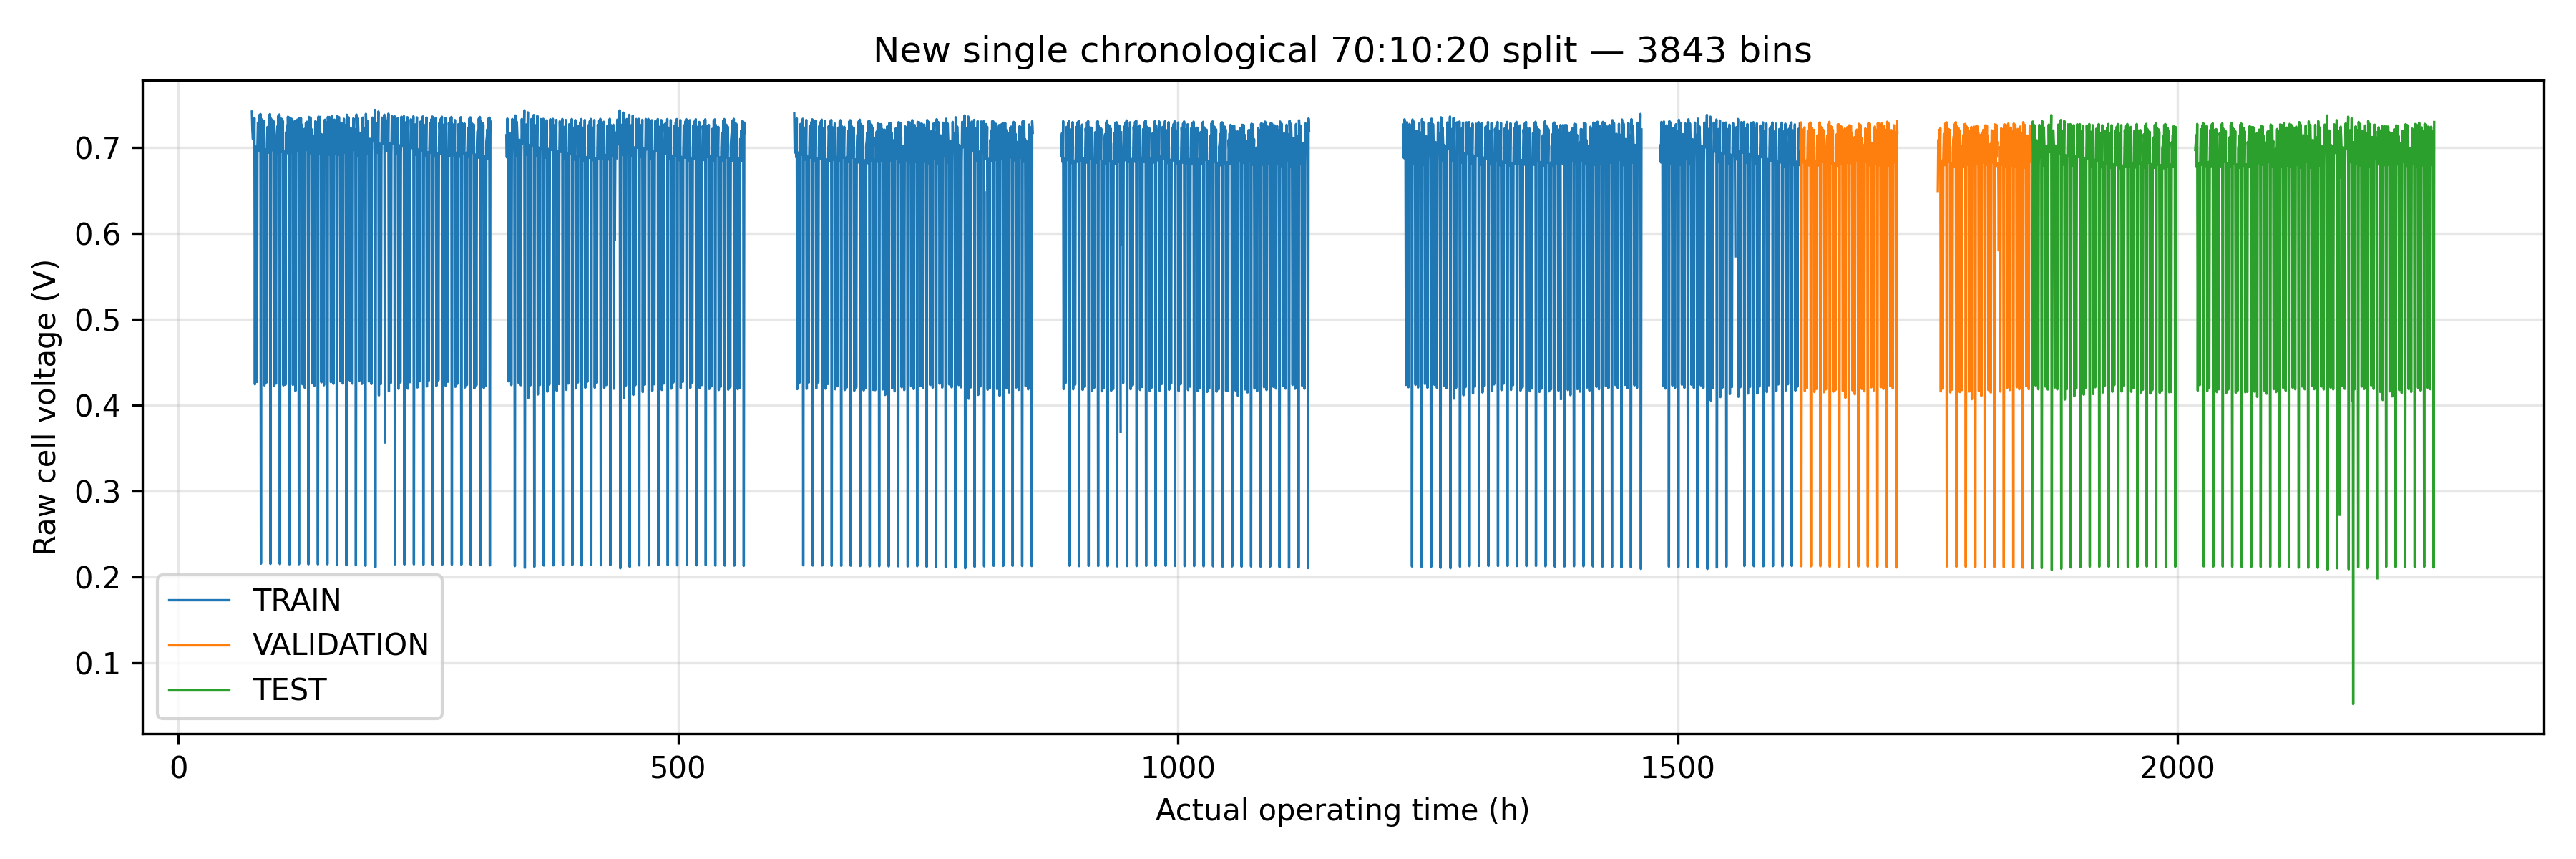

WindowsPath('E:/沈农信电/ PEMFC-SOH+RUL/RENew-PEMFC-2300h-Pytorch/REAL_Paper_File/F2主程序/F2_Training_Outputs/20261019T052754_499042Z_seed202_compare/presentation/01_chronological_split.png')

In [4]:
if SEED == 'all': seeds = list(SUPPORTED_SEEDS)
elif isinstance(SEED, int) and not isinstance(SEED, bool) and SEED in SUPPORTED_SEEDS: seeds = [SEED]
else: raise ValueError('SEED仅允许42、103、193、202、210、212或"all"')
require(FEATURE_MODE in ['top10', 'top11', 'compare'], 'INVALID_FEATURE_MODE')
require(isinstance(MAX_EPOCHS, int) and MAX_EPOCHS > 0 and isinstance(PATIENCE, int) and PATIENCE > 0, 'INVALID_TRAINING_BUDGET')
modes = ['top10', 'top11'] if FEATURE_MODE == 'compare' else [FEATURE_MODE]
environment = configure_environment()
network_audit = verify_network_definitions()
run = OUTPUT_ROOT / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ') + f'_seed{SEED}_{FEATURE_MODE}')
run.mkdir(parents=True, exist_ok=False)
print(f'新实验：{run}。每个模型均从头初始化，不加载旧权重。', flush=True)
frame = pd.read_csv(SOURCE)
require(len(frame) == 3843 and frame.index.equals(pd.RangeIndex(3843)), 'SOURCE_RECORD_IDENTITY_ERROR')
require(frame.bin_end_ophrs2_h.is_monotonic_increasing and frame.bin_end_ophrs2_h.is_unique, 'SOURCE_TIME_ORDER_ERROR')
require(set(frame.bin_valid_for_windows.dropna().unique()).issubset({0, 1}) and not frame.bin_valid_for_windows.isna().any(), 'INVALID_WINDOW_FLAG')
windows, excluded_records, partition_records = {}, [], []
for partition, (start, end) in partitions(len(frame)).items():
    w, excluded = build_windows(frame, start, end)
    require(len(w.origins) > 0 and w.targets.min() >= start and w.targets.max() < end, 'PARTITION_WINDOW_IDENTITY_ERROR')
    windows[partition] = w
    excluded['partition'] = partition; excluded_records.append(excluded)
    partition_records.append(dict(partition=partition, start_row_inclusive=start, end_row_exclusive=end,
        records=end - start, first_operating_h=float(frame.bin_end_ophrs2_h.iloc[start]),
        last_operating_h=float(frame.bin_end_ophrs2_h.iloc[end - 1]), first_datetime=str(frame.first_datetime.iloc[start]),
        last_datetime=str(frame.last_datetime.iloc[end - 1]), legal_origins=len(w.origins), queries=w.y.size,
        unique_target_times=len(np.unique(w.targets)), origins_sha256=array_sha(w.origins), targets_sha256=array_sha(w.targets)))
require(windows['TRAIN'].targets.max() < windows['VALIDATION'].origins.min() and
        windows['VALIDATION'].targets.max() < windows['TEST'].origins.min(), 'LABEL_MODEL_TIME_ISOLATION_ERROR')
save_csv(run, 'PARTITIONS_AND_WINDOWS.csv', partition_records)
save_csv(run, 'EXCLUDED_WINDOWS.csv', pd.concat(excluded_records, ignore_index=True))
for partition, w in windows.items():
    save_csv(run, f'windows/{partition}.csv', dict(origin_row=np.repeat(w.origins, 24), target_row=w.targets.ravel(),
        horizon_step=np.tile(np.arange(1, 25), len(w.origins)), target_age_h=w.target_age_h.ravel()))
display(Markdown('**新协议：一次70% / 10% / 20%时间划分，无交叉验证。** '
    '后20%曾受历史研究反馈影响，只称时间后留评价，不称全新独立盲测。历史成果不参与本次训练结果生成。'))
display(pd.DataFrame(partition_records).iloc[:, :10])
fig, ax = plt.subplots(figsize=(12, 4))
for index, (partition, (start, end)) in enumerate(partitions(len(frame)).items()):
    part = frame.iloc[start:end]
    breaks = part.temporal_segment_id.ne(part.temporal_segment_id.shift()) | part.bin_end_ophrs2_h.diff().sub(.5).abs().gt(1e-6)
    for number, (_, section) in enumerate(part.groupby(breaks.cumsum())):
        ax.plot(section.bin_end_ophrs2_h, section.cell_voltage_mean, color=f'C{index}', lw=.8, label=partition if number == 0 else None)
ax.set(xlabel='Actual operating time (h)', ylabel='Raw cell voltage (V)', title='New single chronological 70:10:20 split — 3843 bins')
ax.legend(); ax.grid(alpha=.3)
save_figure(run, 'presentation/01_chronological_split', fig, frame[['bin_end_ophrs2_h', 'cell_voltage_mean']])

,feature,train_mean,train_standard_deviation
0,cell_voltage_mean,0.645488,0.136656
1,cell_voltage_std,0.001946,0.000399
2,cell_voltage_range,0.006242,0.001246
3,cell_voltage_min,0.490874,0.257114
4,cell_voltage_max,0.795874,0.076663
5,actual_current_A_mean,194.906173,68.038775
6,actual_current_A_std,76.138309,31.205309
7,actual_current_A_peak_to_peak,261.212979,106.696846
8,actual_current_density_A_cm2_mean,0.696091,0.242994
9,actual_current_density_A_cm2_std,0.271925,0.111447


,feature,index,mean_abs_spearman,selected_top10,selected_top11
0,cell_voltage_mean,0,0.630756,True,True
3,cell_voltage_min,3,0.601953,True,True
13,zero_current_fraction,13,0.600158,True,True
11,load_transition_count,11,0.551482,True,True
4,cell_voltage_max,4,0.455820,True,True
9,actual_current_density_A_cm2_std,9,0.362258,True,True
6,actual_current_A_std,6,0.362235,True,True
7,actual_current_A_peak_to_peak,7,0.278723,True,True
10,actual_current_density_A_cm2_peak_to_peak,10,0.278508,True,True
8,actual_current_density_A_cm2_mean,8,0.227676,True,True


**排名仅使用本次Train，用于检查和展示。** Top10按要求固定原索引；Top11只增加索引5，不按Validation/Test重新排序选择，也不运行Top14。未参与的标准化通道真正置零。

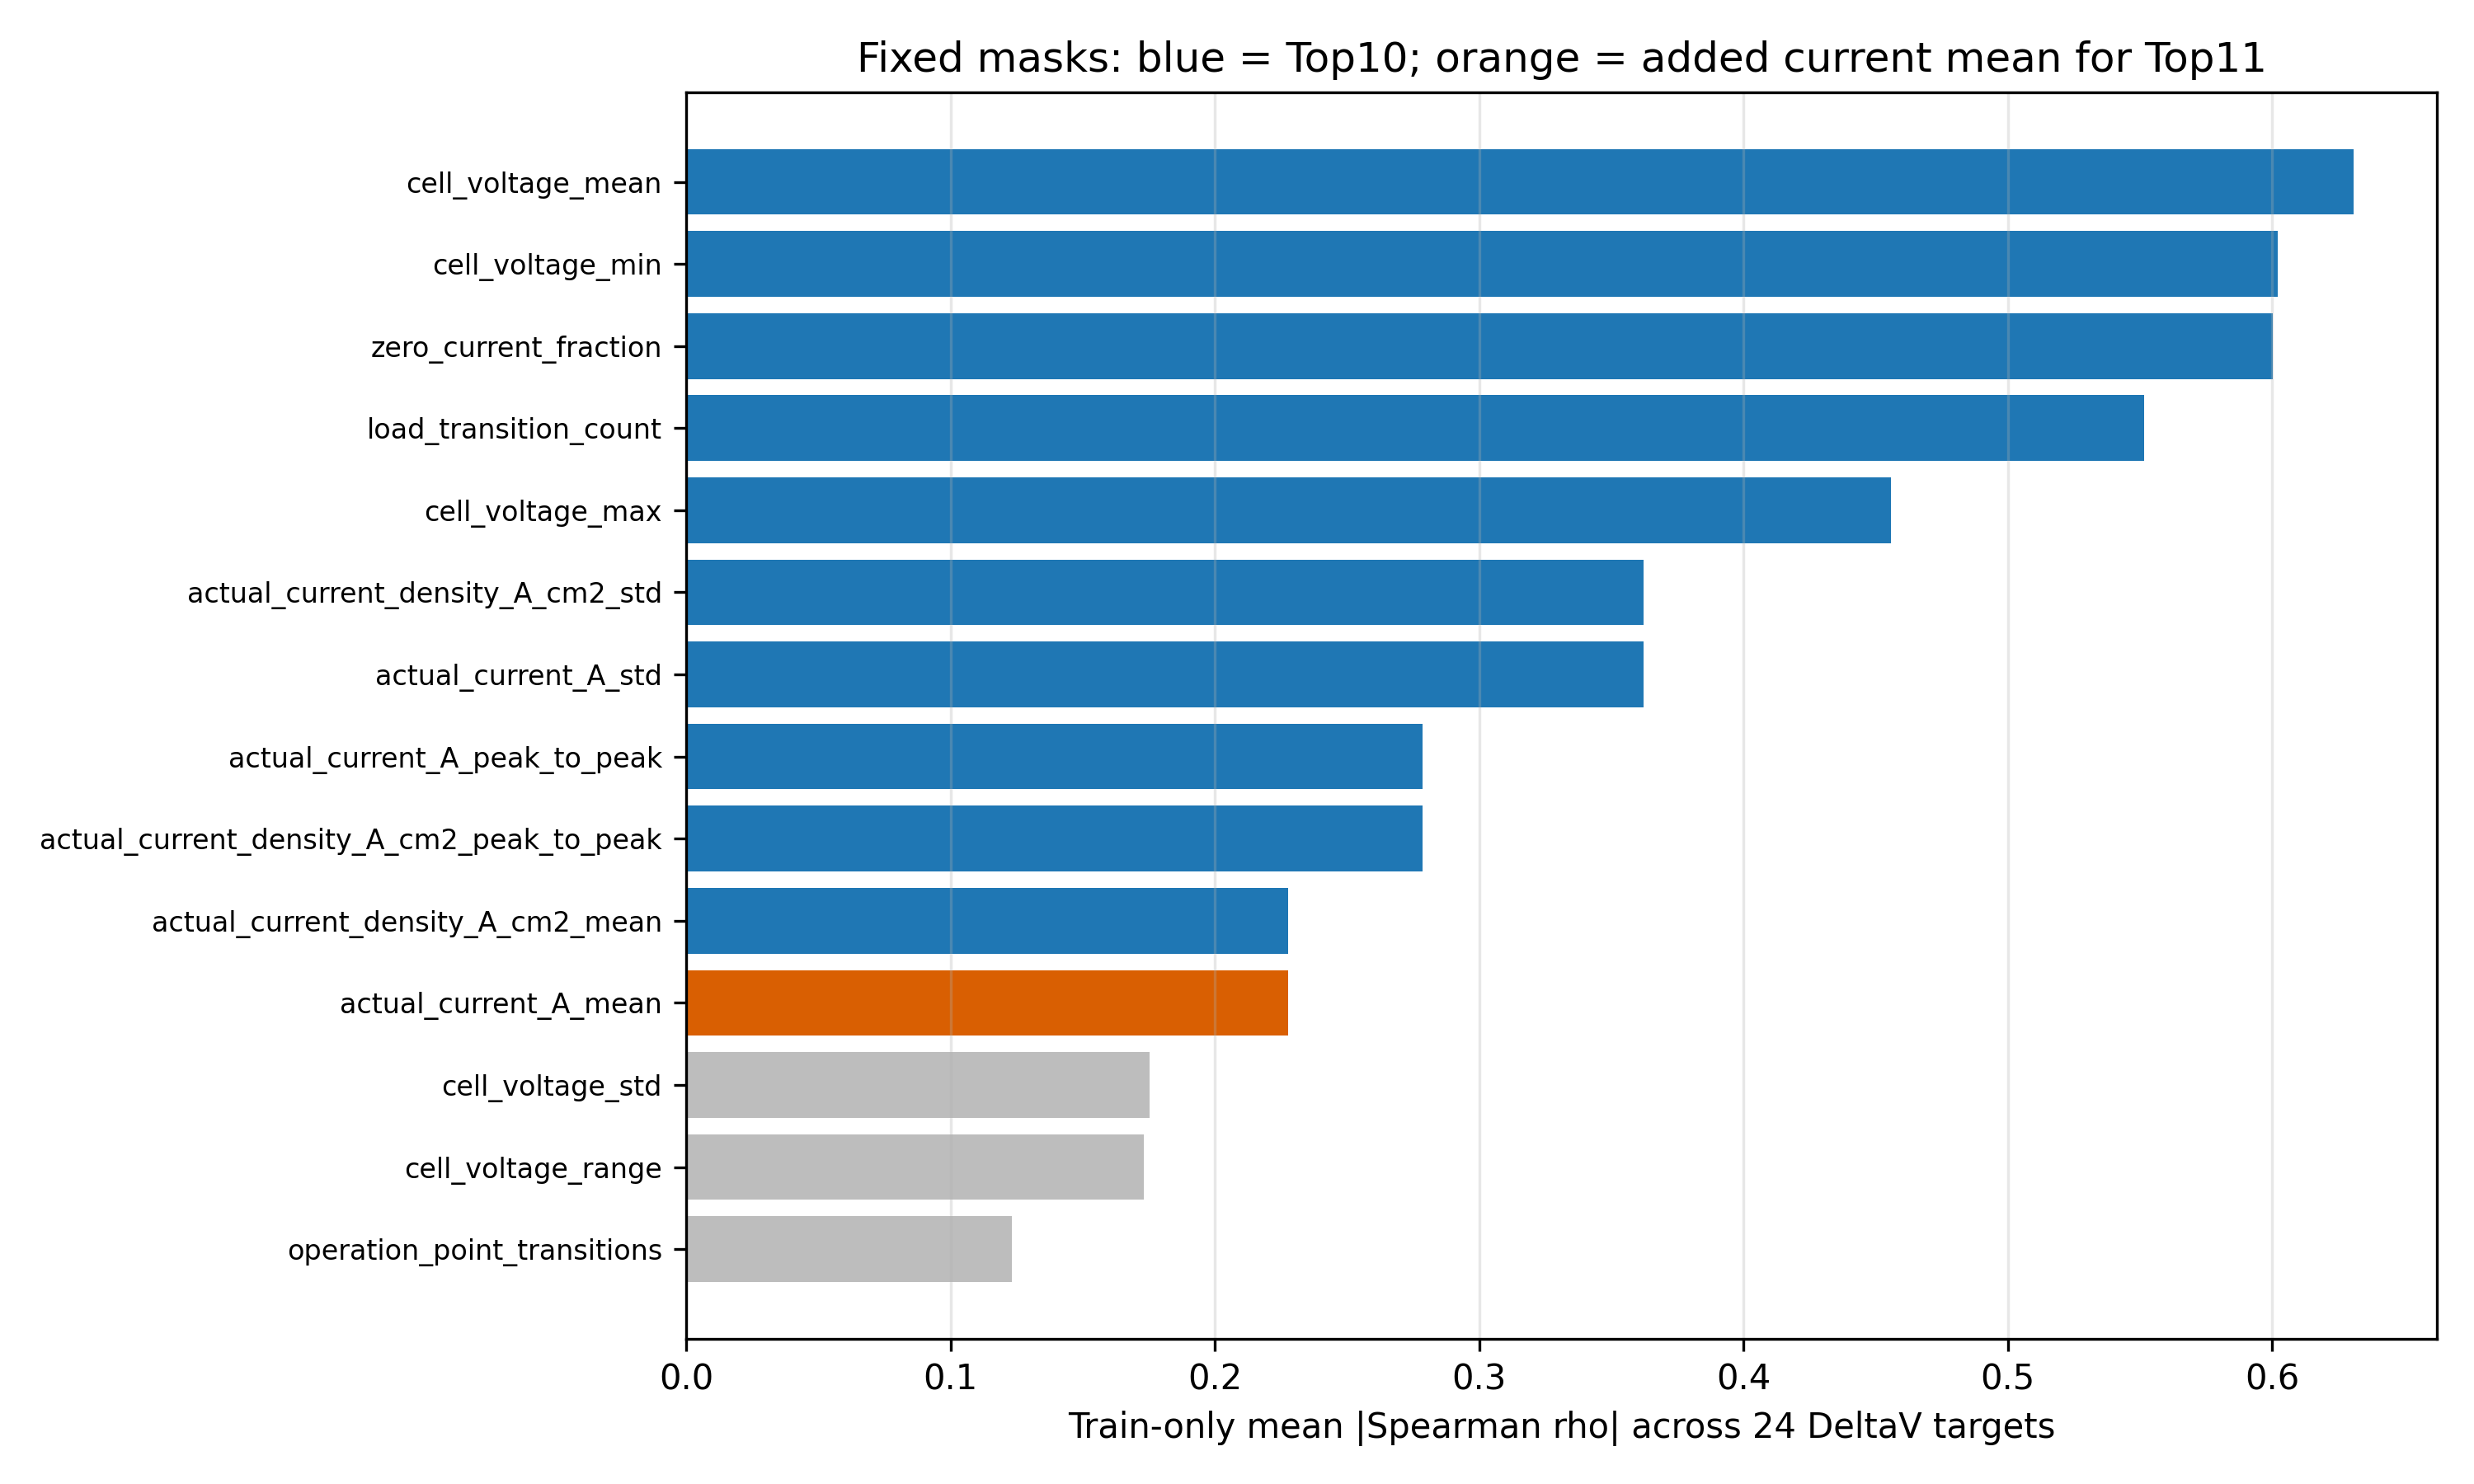

WindowsPath('E:/沈农信电/ PEMFC-SOH+RUL/RENew-PEMFC-2300h-Pytorch/REAL_Paper_File/F2主程序/F2_Training_Outputs/20261019T052754_499042Z_seed202_compare/presentation/02_features.png')

In [5]:
scaler = TrainScaler().fit(windows['TRAIN'].x_raw)
stats = pd.DataFrame(dict(feature=FEATURES, train_mean=scaler.mean, train_standard_deviation=scaler.scale))
display(stats)
save_csv(run, 'TRAIN_ONLY_SCALER.csv', stats)
save_json(run, 'PREPROCESSOR.json', dict(mean=scaler.mean.tolist(), scale=scaler.scale.tolist(),
    target_scale_V=scaler.target_scale, fitted_partition='TRAIN', masks=MASKS, EWMA_alpha=.3))
ranking = spearman_train_only(windows['TRAIN'])
display(ranking)
display(Markdown('**排名仅使用本次Train，用于检查和展示。** Top10按要求固定原索引；Top11只增加索引5，'
                 '不按Validation/Test重新排序选择，也不运行Top14。未参与的标准化通道真正置零。'))
fig, ax = plt.subplots(figsize=(10, 6))
ordered = ranking.iloc[::-1]
ax.barh(ordered.feature, ordered.mean_abs_spearman,
    color=['#d95f02' if i == 5 else '#1f77b4' if i in MASKS['top10'] else '#bdbdbd' for i in ordered['index']])
ax.set(xlabel='Train-only mean |Spearman rho| across 24 DeltaV targets', title='Fixed masks: blue = Top10; orange = added current mean for Top11')
ax.tick_params(axis='y', labelsize=8); ax.grid(axis='x', alpha=.3)
save_figure(run, 'presentation/02_features', fig, ranking)

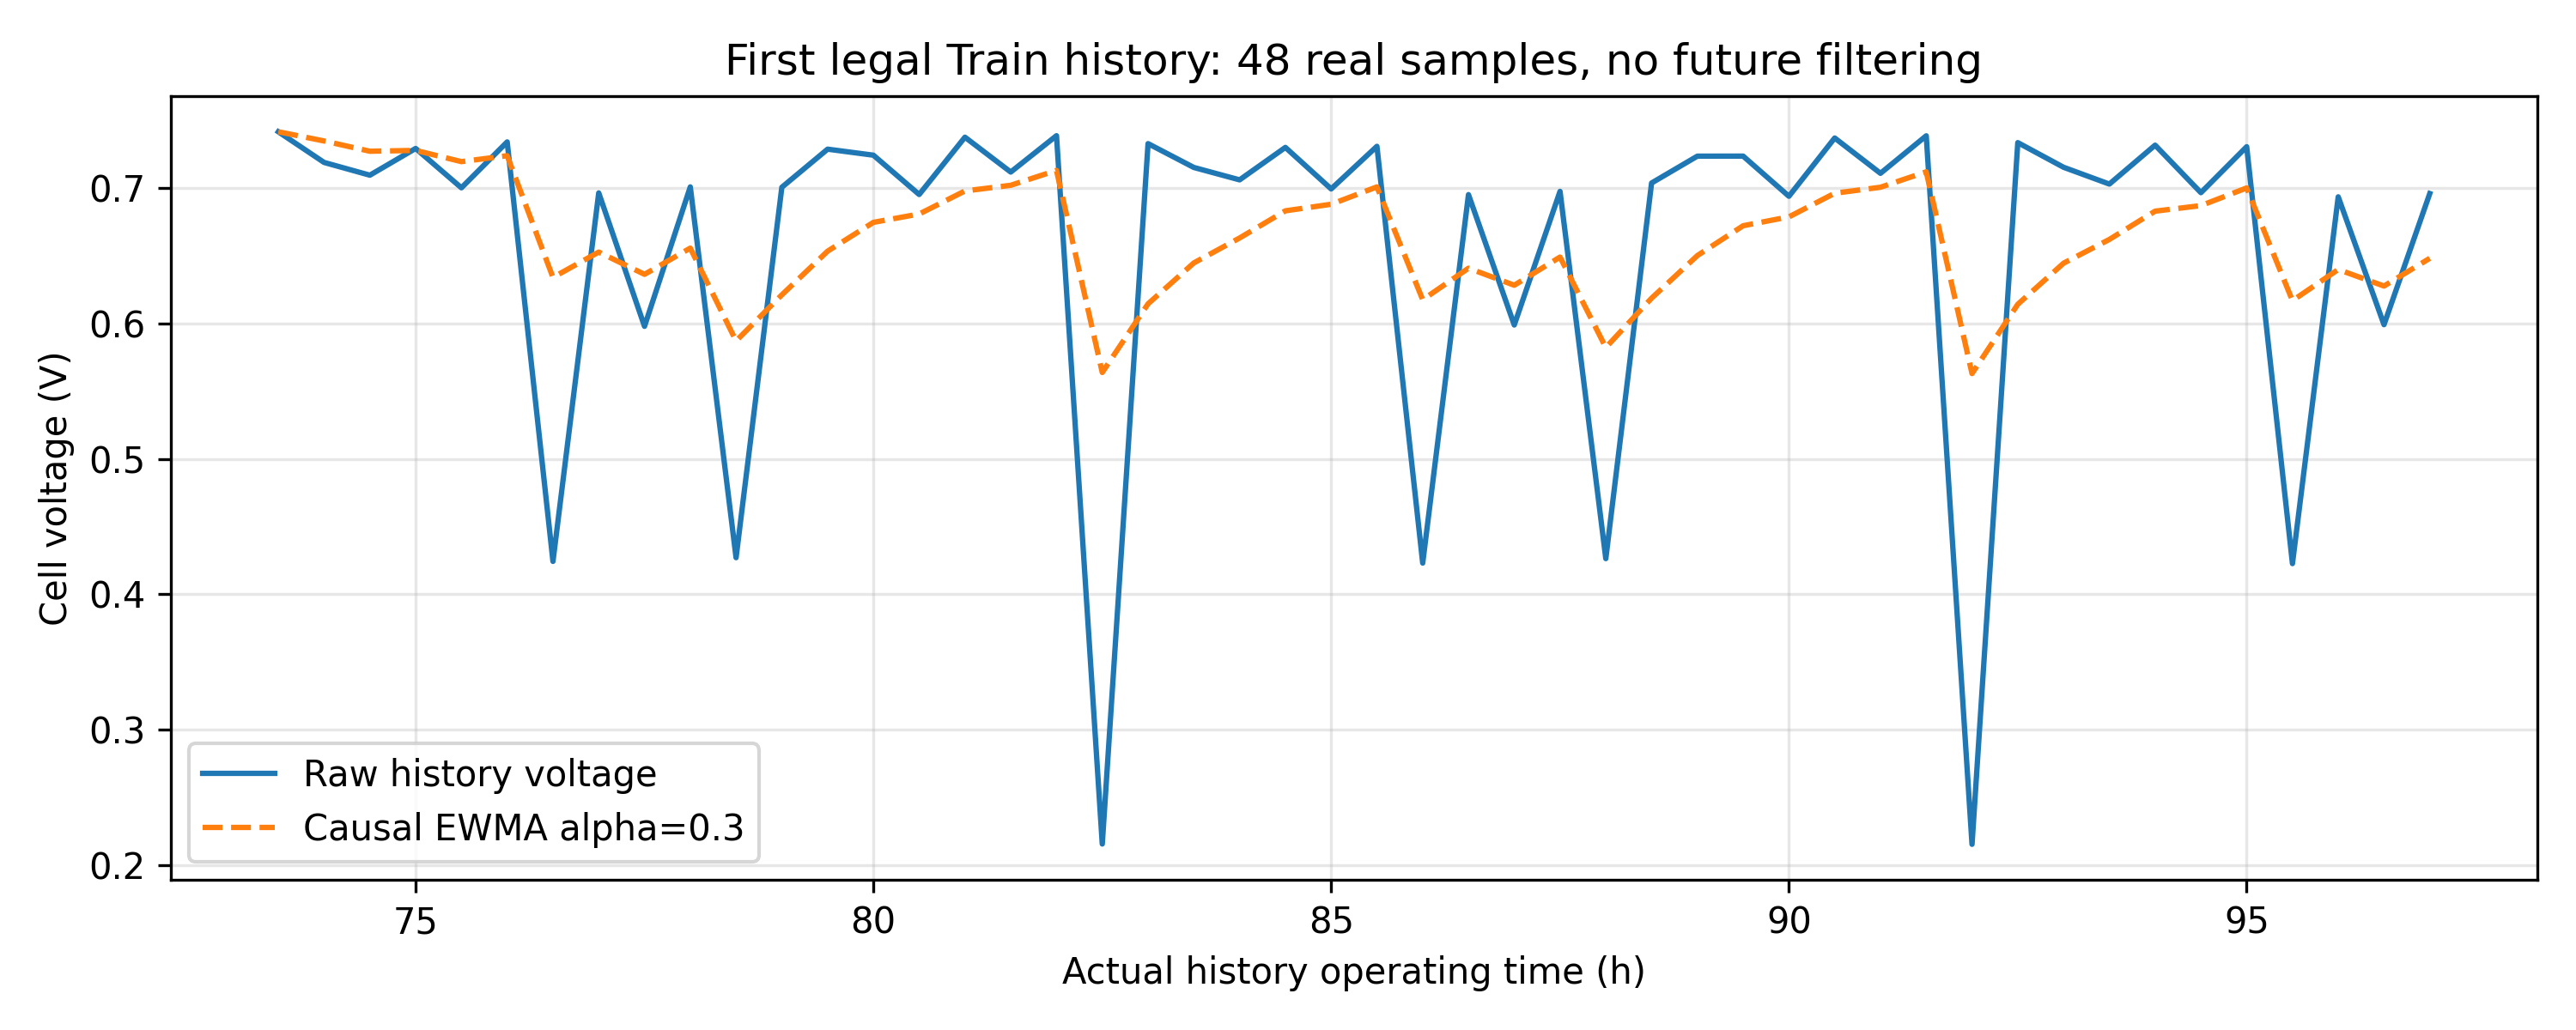

,frozen_value
learning_rate,0.000961
weight_decay,0.000007
batch_size,32
dropout,0.1
hidden_size,64
hidden_continuous_size,32
attention_head_size,4
lstm_layers,1
gradient_clip_norm,1.0
optimizer,AdamW


训练配置和评价规则已在首次梯度更新前保存；不运行Optuna，不因后留成绩修改方案。


In [6]:
prepared_by_mode = {mode: {partition: masked_inputs(w.x_raw, scaler, mode) for partition, w in windows.items()} for mode in modes}
mask_audits = []
for mode in modes:
    for partition, prepared in prepared_by_mode[mode].items():
        require(np.all(prepared[:, :, [i for i in range(14) if i not in MASKS[mode]]] == 0), 'MASK_NOT_APPLIED')
        mask_audits.append(dict(feature_mode=mode, partition=partition, prepared_sha256=array_sha(prepared),
                               mean_current_nonzero=int(np.count_nonzero(prepared[:, :, 5]))))
if len(modes) == 2:
    for partition in windows:
        x10, x11 = prepared_by_mode['top10'][partition], prepared_by_mode['top11'][partition]
        require(np.array_equal(x10[:, :, [i for i in range(14) if i != 5]], x11[:, :, [i for i in range(14) if i != 5]])
                and np.all(x10[:, :, 5] == 0) and np.count_nonzero(x11[:, :, 5]) > 0, 'TOP11_MUST_ONLY_ADD_INDEX5')
save_csv(run, 'MASK_APPLICATION_AUDIT.csv', mask_audits)
raw_example = windows['TRAIN'].x_raw[:1]
filtered_example = causal_ewma(raw_example)
example_data = pd.DataFrame(dict(age_h=windows['TRAIN'].origin_age_h[0] - np.arange(47, -1, -1) * .5,
    raw_voltage_V=raw_example[0, :, 0], EWMA_voltage_V=filtered_example[0, :, 0]))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(example_data.age_h, example_data.raw_voltage_V, lw=1.5, label='Raw history voltage')
ax.plot(example_data.age_h, example_data.EWMA_voltage_V, lw=1.5, ls='--', label='Causal EWMA alpha=0.3')
ax.set(xlabel='Actual history operating time (h)', ylabel='Cell voltage (V)', title='First legal Train history: 48 real samples, no future filtering')
ax.legend(); ax.grid(alpha=.3)
save_figure(run, 'presentation/03_causal_EWMA', fig, example_data)
# A descriptive grouping only; fixed using unique TRAIN target voltages before any holdout scoring.
train_targets = np.unique(windows['TRAIN'].targets)
clusterer = KMeans(n_clusters=4, random_state=202, n_init=10).fit(frame.cell_voltage_mean.to_numpy()[train_targets, None])
voltage_centres = np.sort(clusterer.cluster_centers_.ravel())
voltage_edges = (voltage_centres[1:] + voltage_centres[:-1]) / 2
protocol = dict(name='F2_SINGLE_70_10_20_FRESH_TRAIN_TOP10_TOP11', created_utc=datetime.now(timezone.utc).isoformat(),
    source=str(SOURCE), data_rows=len(frame), data_sha256=sha(SOURCE), seeds=seeds, feature_modes=modes,
    masks=MASKS, partitions=partition_records, hyperparameters=HYPERPARAMETERS,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, validation_selection='minimum full Validation standardized RMSE; patience counts epochs',
    history=48, horizon=24, resolution_h=.5, target='future raw voltage minus raw origin voltage',
    target_scale_V=scaler.target_scale, no_historical_weights_or_prediction_caches=True,
    descriptive_voltage_groups=dict(method='fixed four 1D KMeans groups fit only to unique TRAIN target voltages',
        centres_V=voltage_centres.tolist(), edges_V=voltage_edges.tolist(), proves_four_physical_states=False,
        target_current_used='post-hoc scatter coloring only, never a future model input'),
    scientific_status='new exploratory chronological holdout; not an unseen independent blind Test',
    code_sha256=sha(FOLDER / 'F2_Train_Interactive.py'), environment=environment, network=network_audit)
save_json(run, 'PROTOCOL_BEFORE_TRAINING.json', protocol)
display(pd.DataFrame([HYPERPARAMETERS | dict(max_epochs=MAX_EPOCHS, patience=PATIENCE)]).T.rename(columns={0: 'frozen_value'}))
print('训练配置和评价规则已在首次梯度更新前保存；不运行Optuna，不因后留成绩修改方案。', flush=True)

开始从头训练 Seed 202 / top10：1750 Train窗口，218 Validation窗口
Seed 202 top10 | Epoch 1/450 | Train Loss 1.847481 | Validation Loss 1.143006 | Best Epoch 1 | Patience 0/40


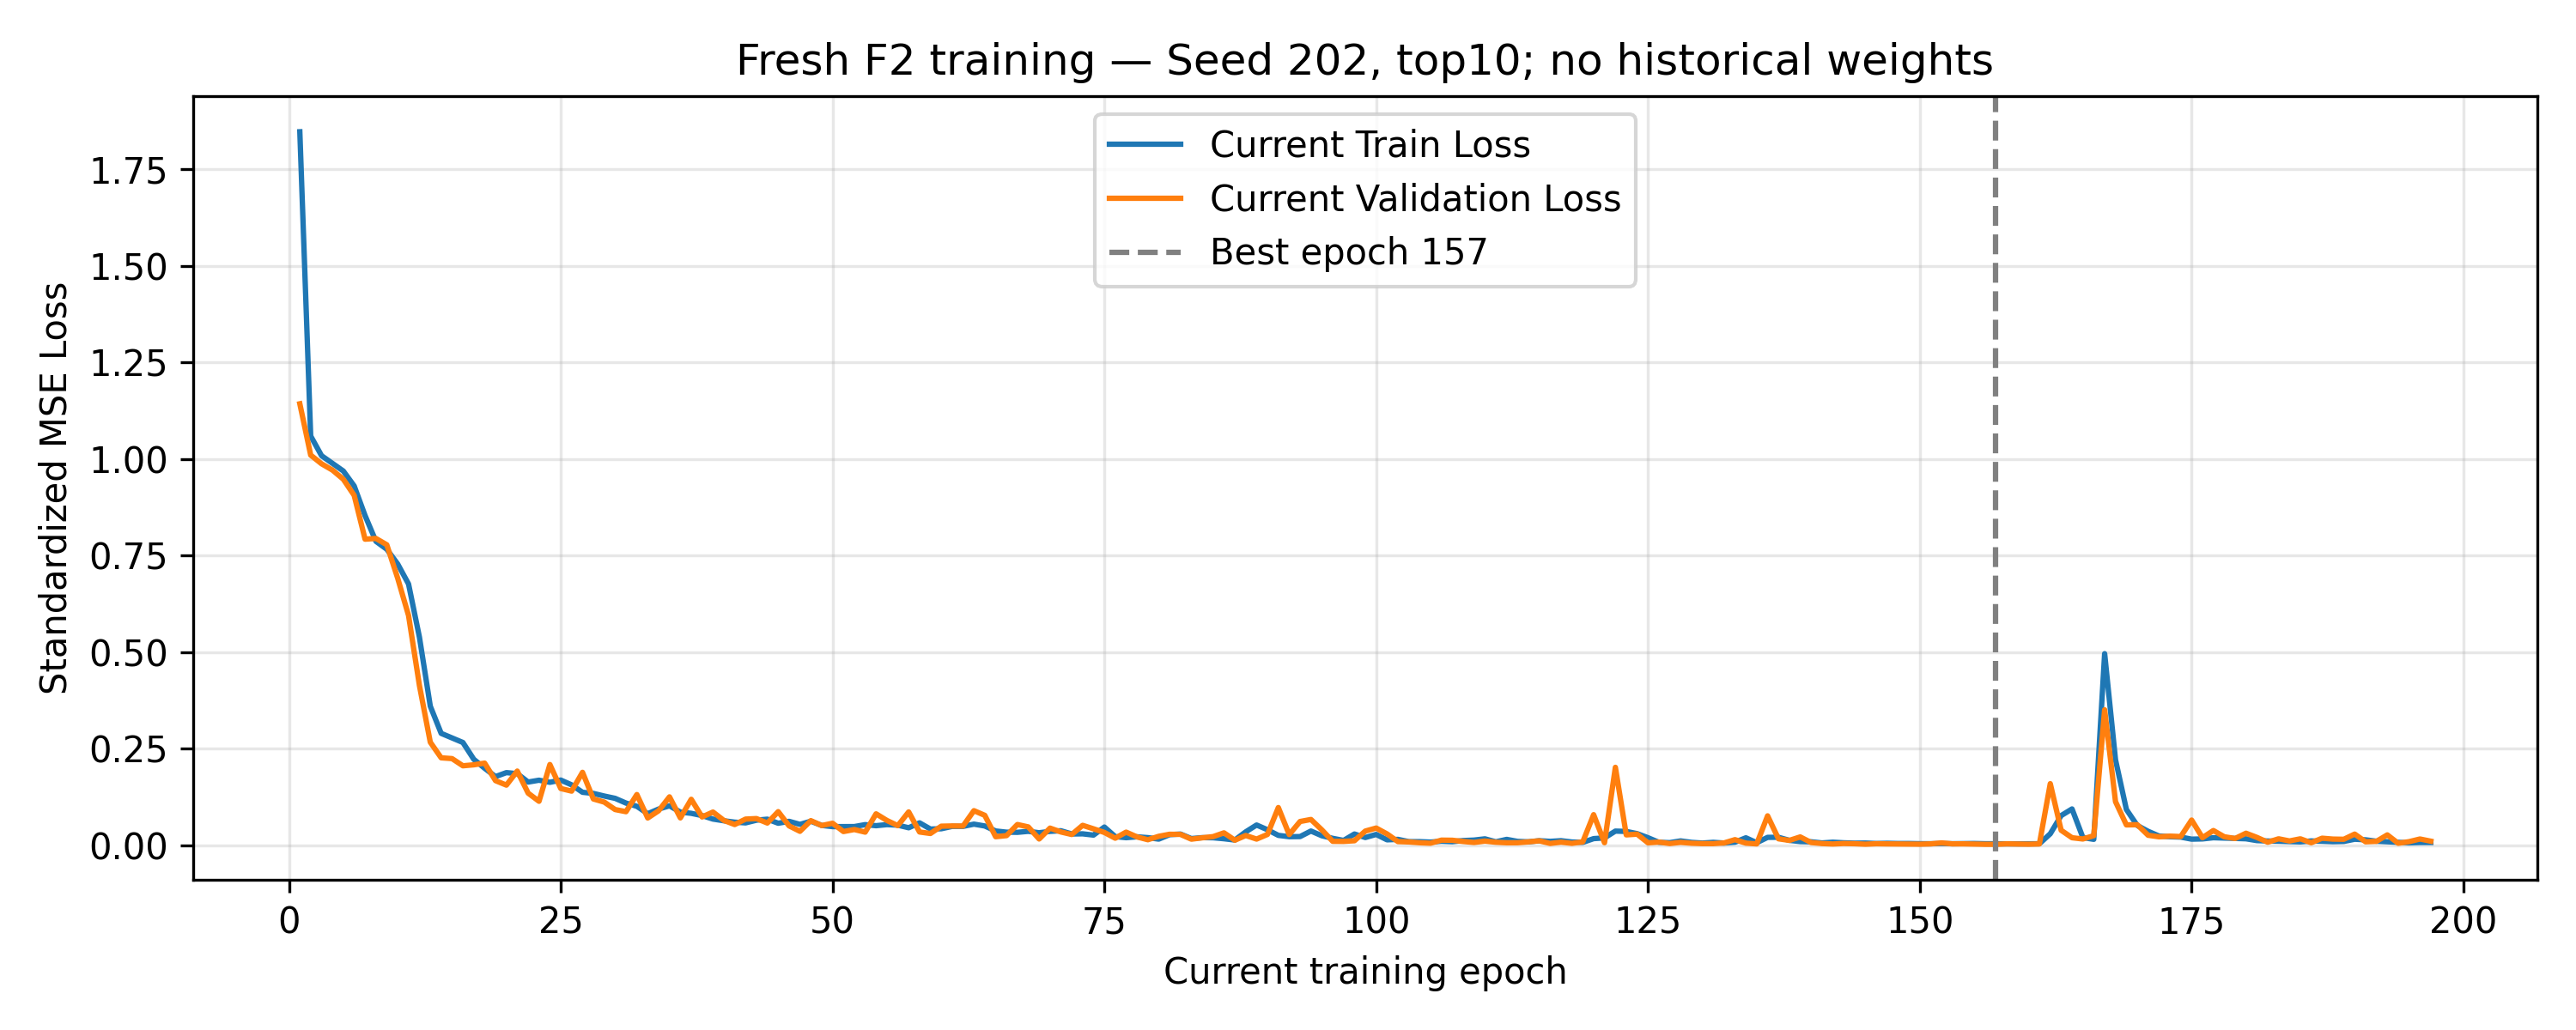

Seed 202 top10 | Epoch 2/450 | Train Loss 1.059524 | Validation Loss 1.010126 | Best Epoch 2 | Patience 0/40
Seed 202 top10 | Epoch 3/450 | Train Loss 1.008559 | Validation Loss 0.987617 | Best Epoch 3 | Patience 0/40
Seed 202 top10 | Epoch 4/450 | Train Loss 0.988855 | Validation Loss 0.971310 | Best Epoch 4 | Patience 0/40
Seed 202 top10 | Epoch 5/450 | Train Loss 0.968925 | Validation Loss 0.947636 | Best Epoch 5 | Patience 0/40
Seed 202 top10 | Epoch 6/450 | Train Loss 0.930184 | Validation Loss 0.905826 | Best Epoch 6 | Patience 0/40
Seed 202 top10 | Epoch 7/450 | Train Loss 0.853583 | Validation Loss 0.792388 | Best Epoch 7 | Patience 0/40
Seed 202 top10 | Epoch 8/450 | Train Loss 0.786796 | Validation Loss 0.794281 | Best Epoch 7 | Patience 1/40
Seed 202 top10 | Epoch 9/450 | Train Loss 0.766328 | Validation Loss 0.777863 | Best Epoch 9 | Patience 0/40
Seed 202 top10 | Epoch 10/450 | Train Loss 0.728165 | Validation Loss 0.691482 | Best Epoch 10 | Patience 0/40
Seed 202 top10 | 

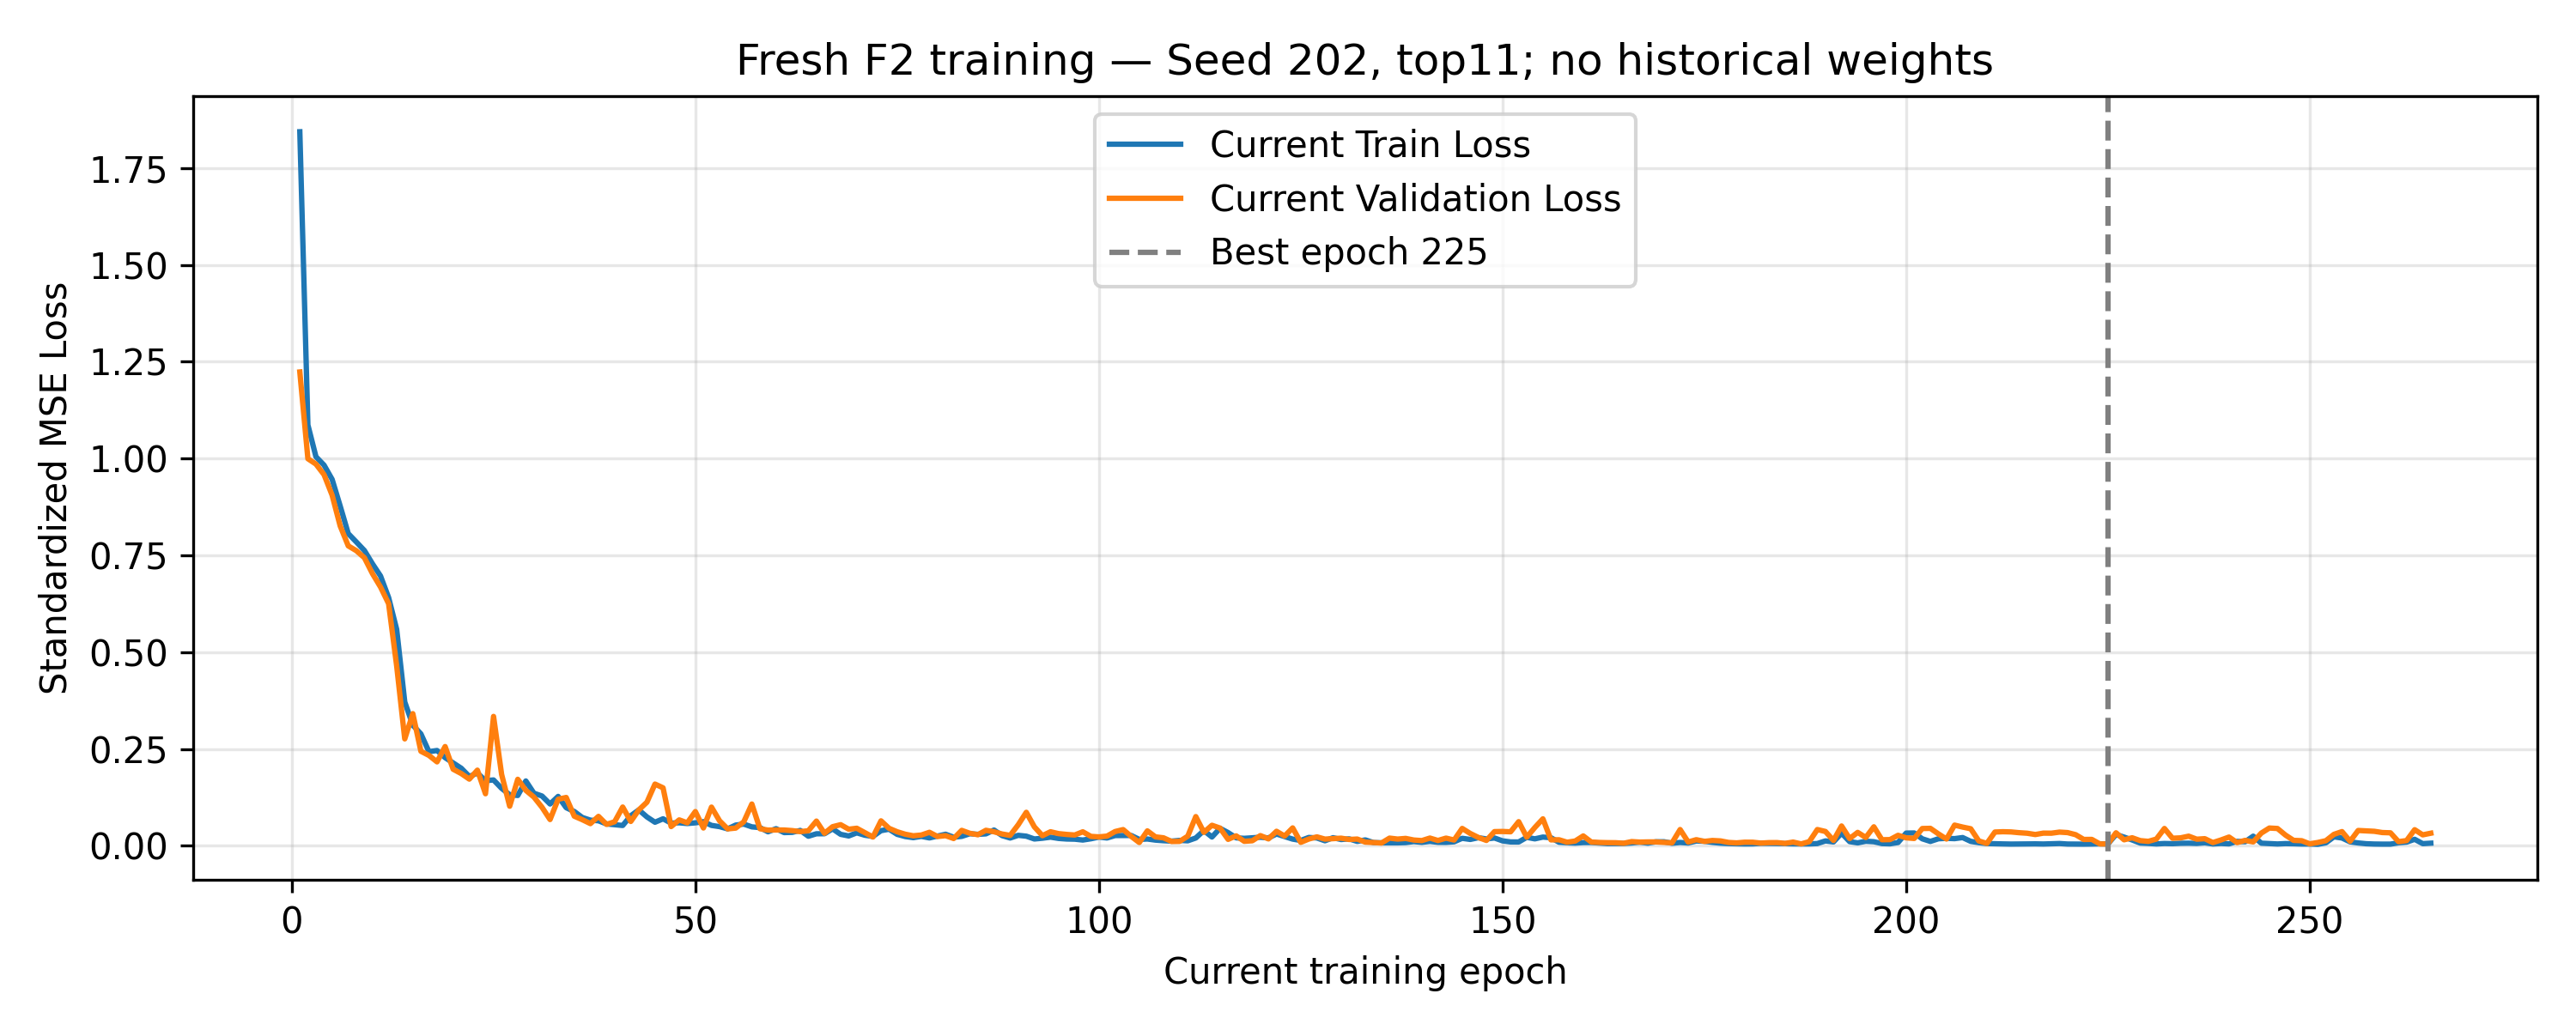

Seed 202 top11 | Epoch 2/450 | Train Loss 1.086676 | Validation Loss 0.999419 | Best Epoch 2 | Patience 0/40
Seed 202 top11 | Epoch 3/450 | Train Loss 1.004435 | Validation Loss 0.985512 | Best Epoch 3 | Patience 0/40
Seed 202 top11 | Epoch 4/450 | Train Loss 0.982879 | Validation Loss 0.958268 | Best Epoch 4 | Patience 0/40
Seed 202 top11 | Epoch 5/450 | Train Loss 0.946166 | Validation Loss 0.905296 | Best Epoch 5 | Patience 0/40
Seed 202 top11 | Epoch 6/450 | Train Loss 0.877242 | Validation Loss 0.825811 | Best Epoch 6 | Patience 0/40
Seed 202 top11 | Epoch 7/450 | Train Loss 0.806017 | Validation Loss 0.774351 | Best Epoch 7 | Patience 0/40
Seed 202 top11 | Epoch 8/450 | Train Loss 0.784422 | Validation Loss 0.761861 | Best Epoch 8 | Patience 0/40
Seed 202 top11 | Epoch 9/450 | Train Loss 0.762361 | Validation Loss 0.743688 | Best Epoch 9 | Patience 0/40
Seed 202 top11 | Epoch 10/450 | Train Loss 0.728034 | Validation Loss 0.702641 | Best Epoch 10 | Patience 0/40
Seed 202 top11 | 

In [7]:
training_ledgers = []
for seed in seeds:
    for mode in modes:
        ledger = train_fresh(run, seed, mode, windows['TRAIN'], windows['VALIDATION'], prepared_by_mode[mode], scaler, protocol)
        training_ledgers.append(ledger)
    if len(modes) == 2:
        same_seed = [row for row in training_ledgers if row['seed'] == seed]
        require(same_seed[0]['initialization_sha256'] == same_seed[1]['initialization_sha256'], 'PAIRED_INITIALIZATION_MISMATCH')
        a = read_csv(run / f'seed{seed}/top10/training_history.csv')
        b = read_csv(run / f'seed{seed}/top11/training_history.csv')
        common = min(len(a), len(b))
        require(np.array_equal(a.sampler_order_sha256.iloc[:common], b.sampler_order_sha256.iloc[:common]), 'PAIRED_SAMPLER_ORDER_MISMATCH')
save_json(run, 'COHORT_TRAINING_FROZEN.json', dict(status='ALL_REQUESTED_MODELS_TRAINED',
    frozen_utc=datetime.now(timezone.utc).isoformat(), models=training_ledgers, holdout_metrics_observed=False))
print('本次全部请求的模型均已训练完成并冻结最佳权重；现在才开始后留评价。', flush=True)

本次最佳权重推理：Seed 202 top10 TRAIN，1750个窗口
本次最佳权重推理：Seed 202 top10 VALIDATION，218个窗口
本次最佳权重推理：Seed 202 top10 TEST，527个窗口


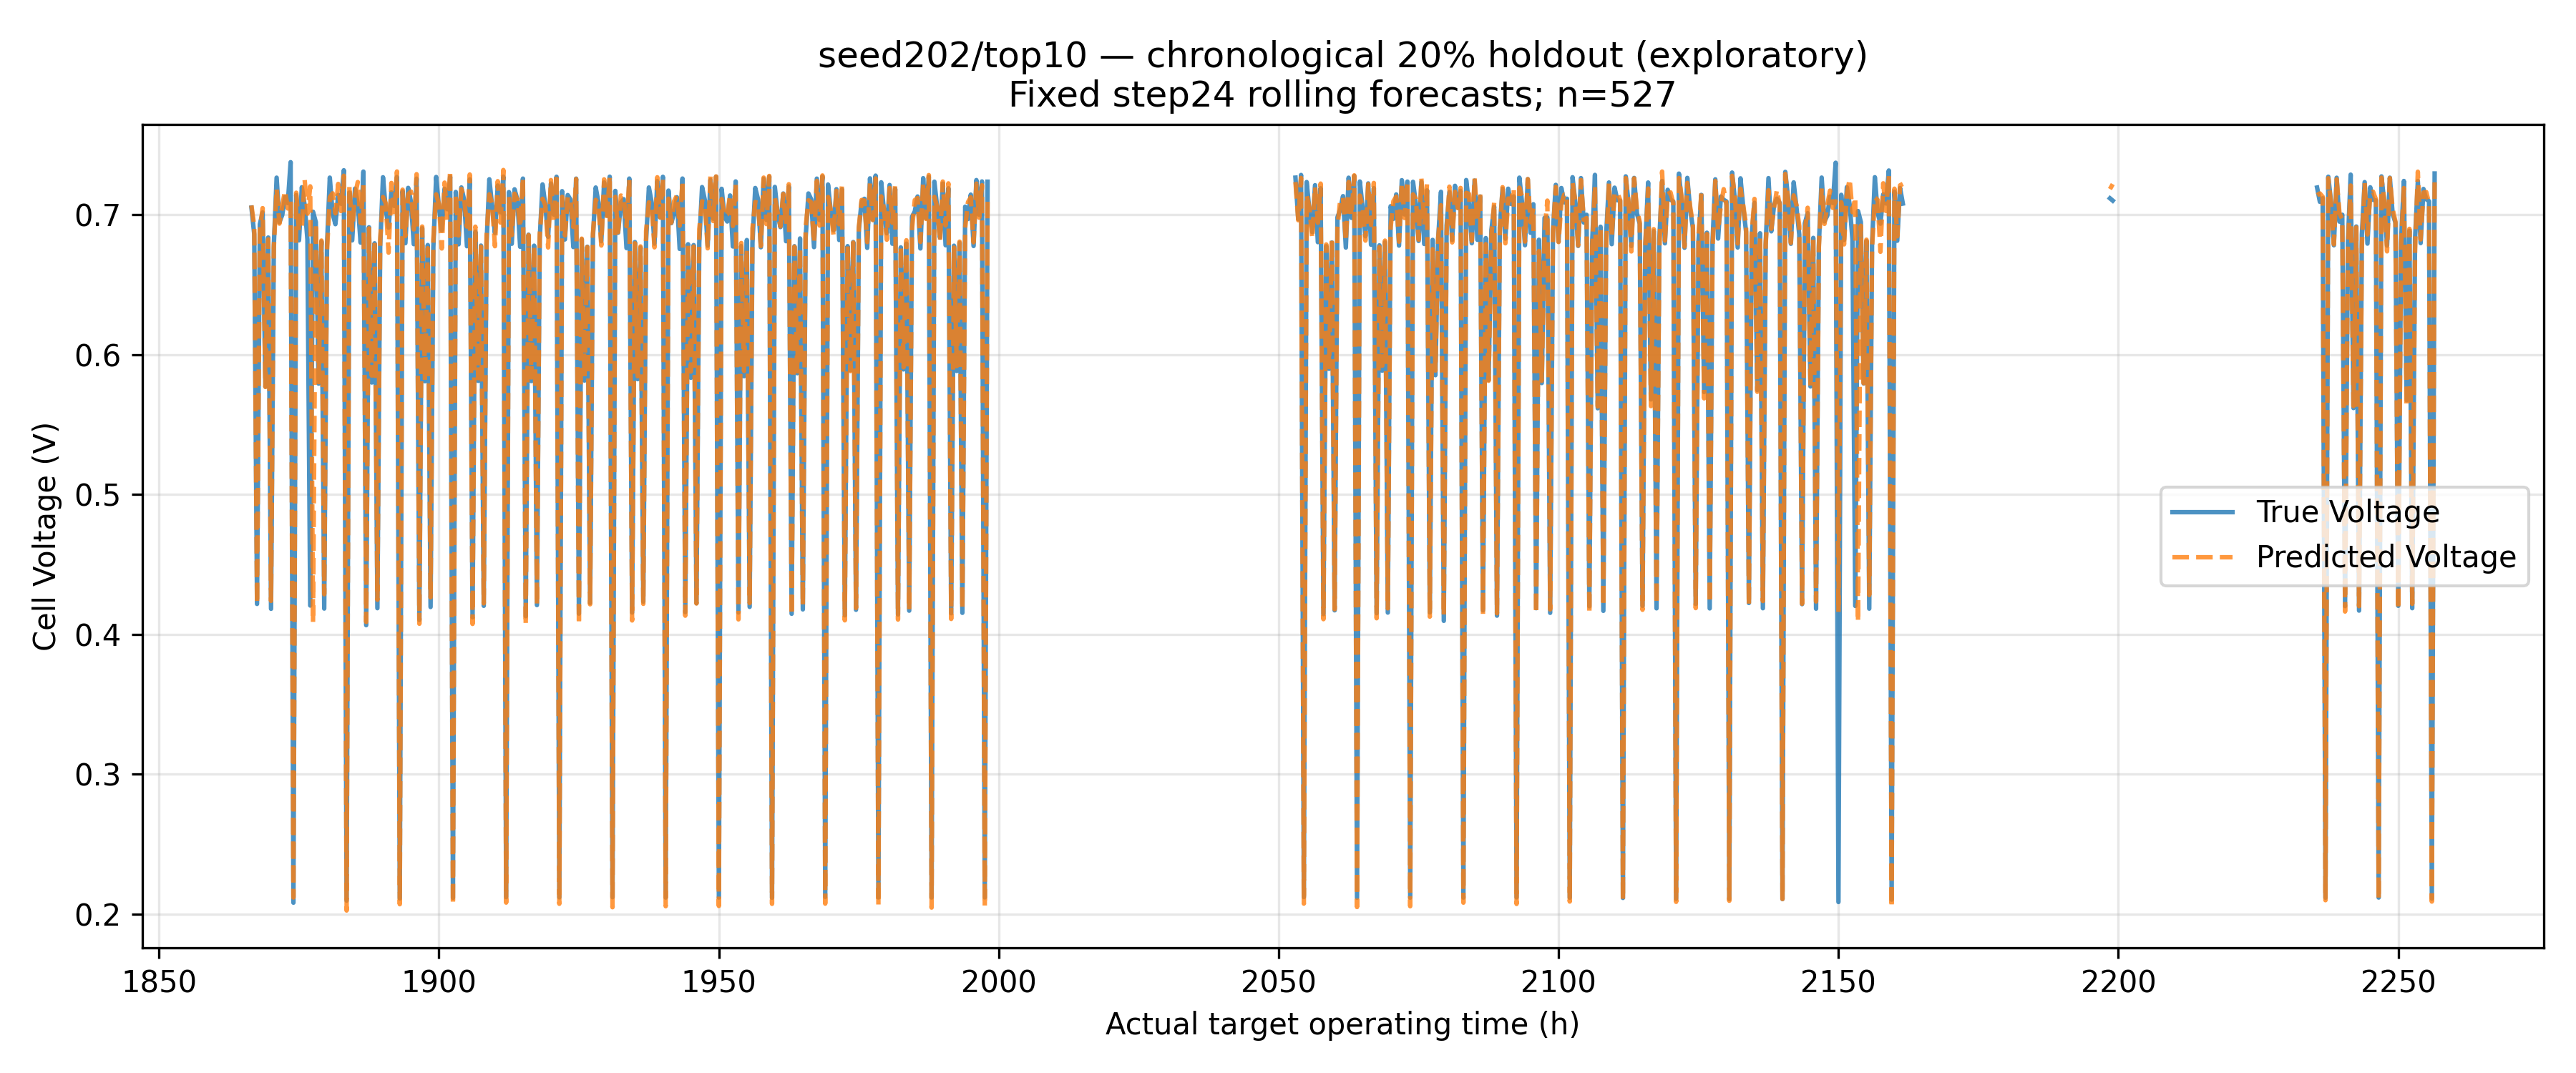

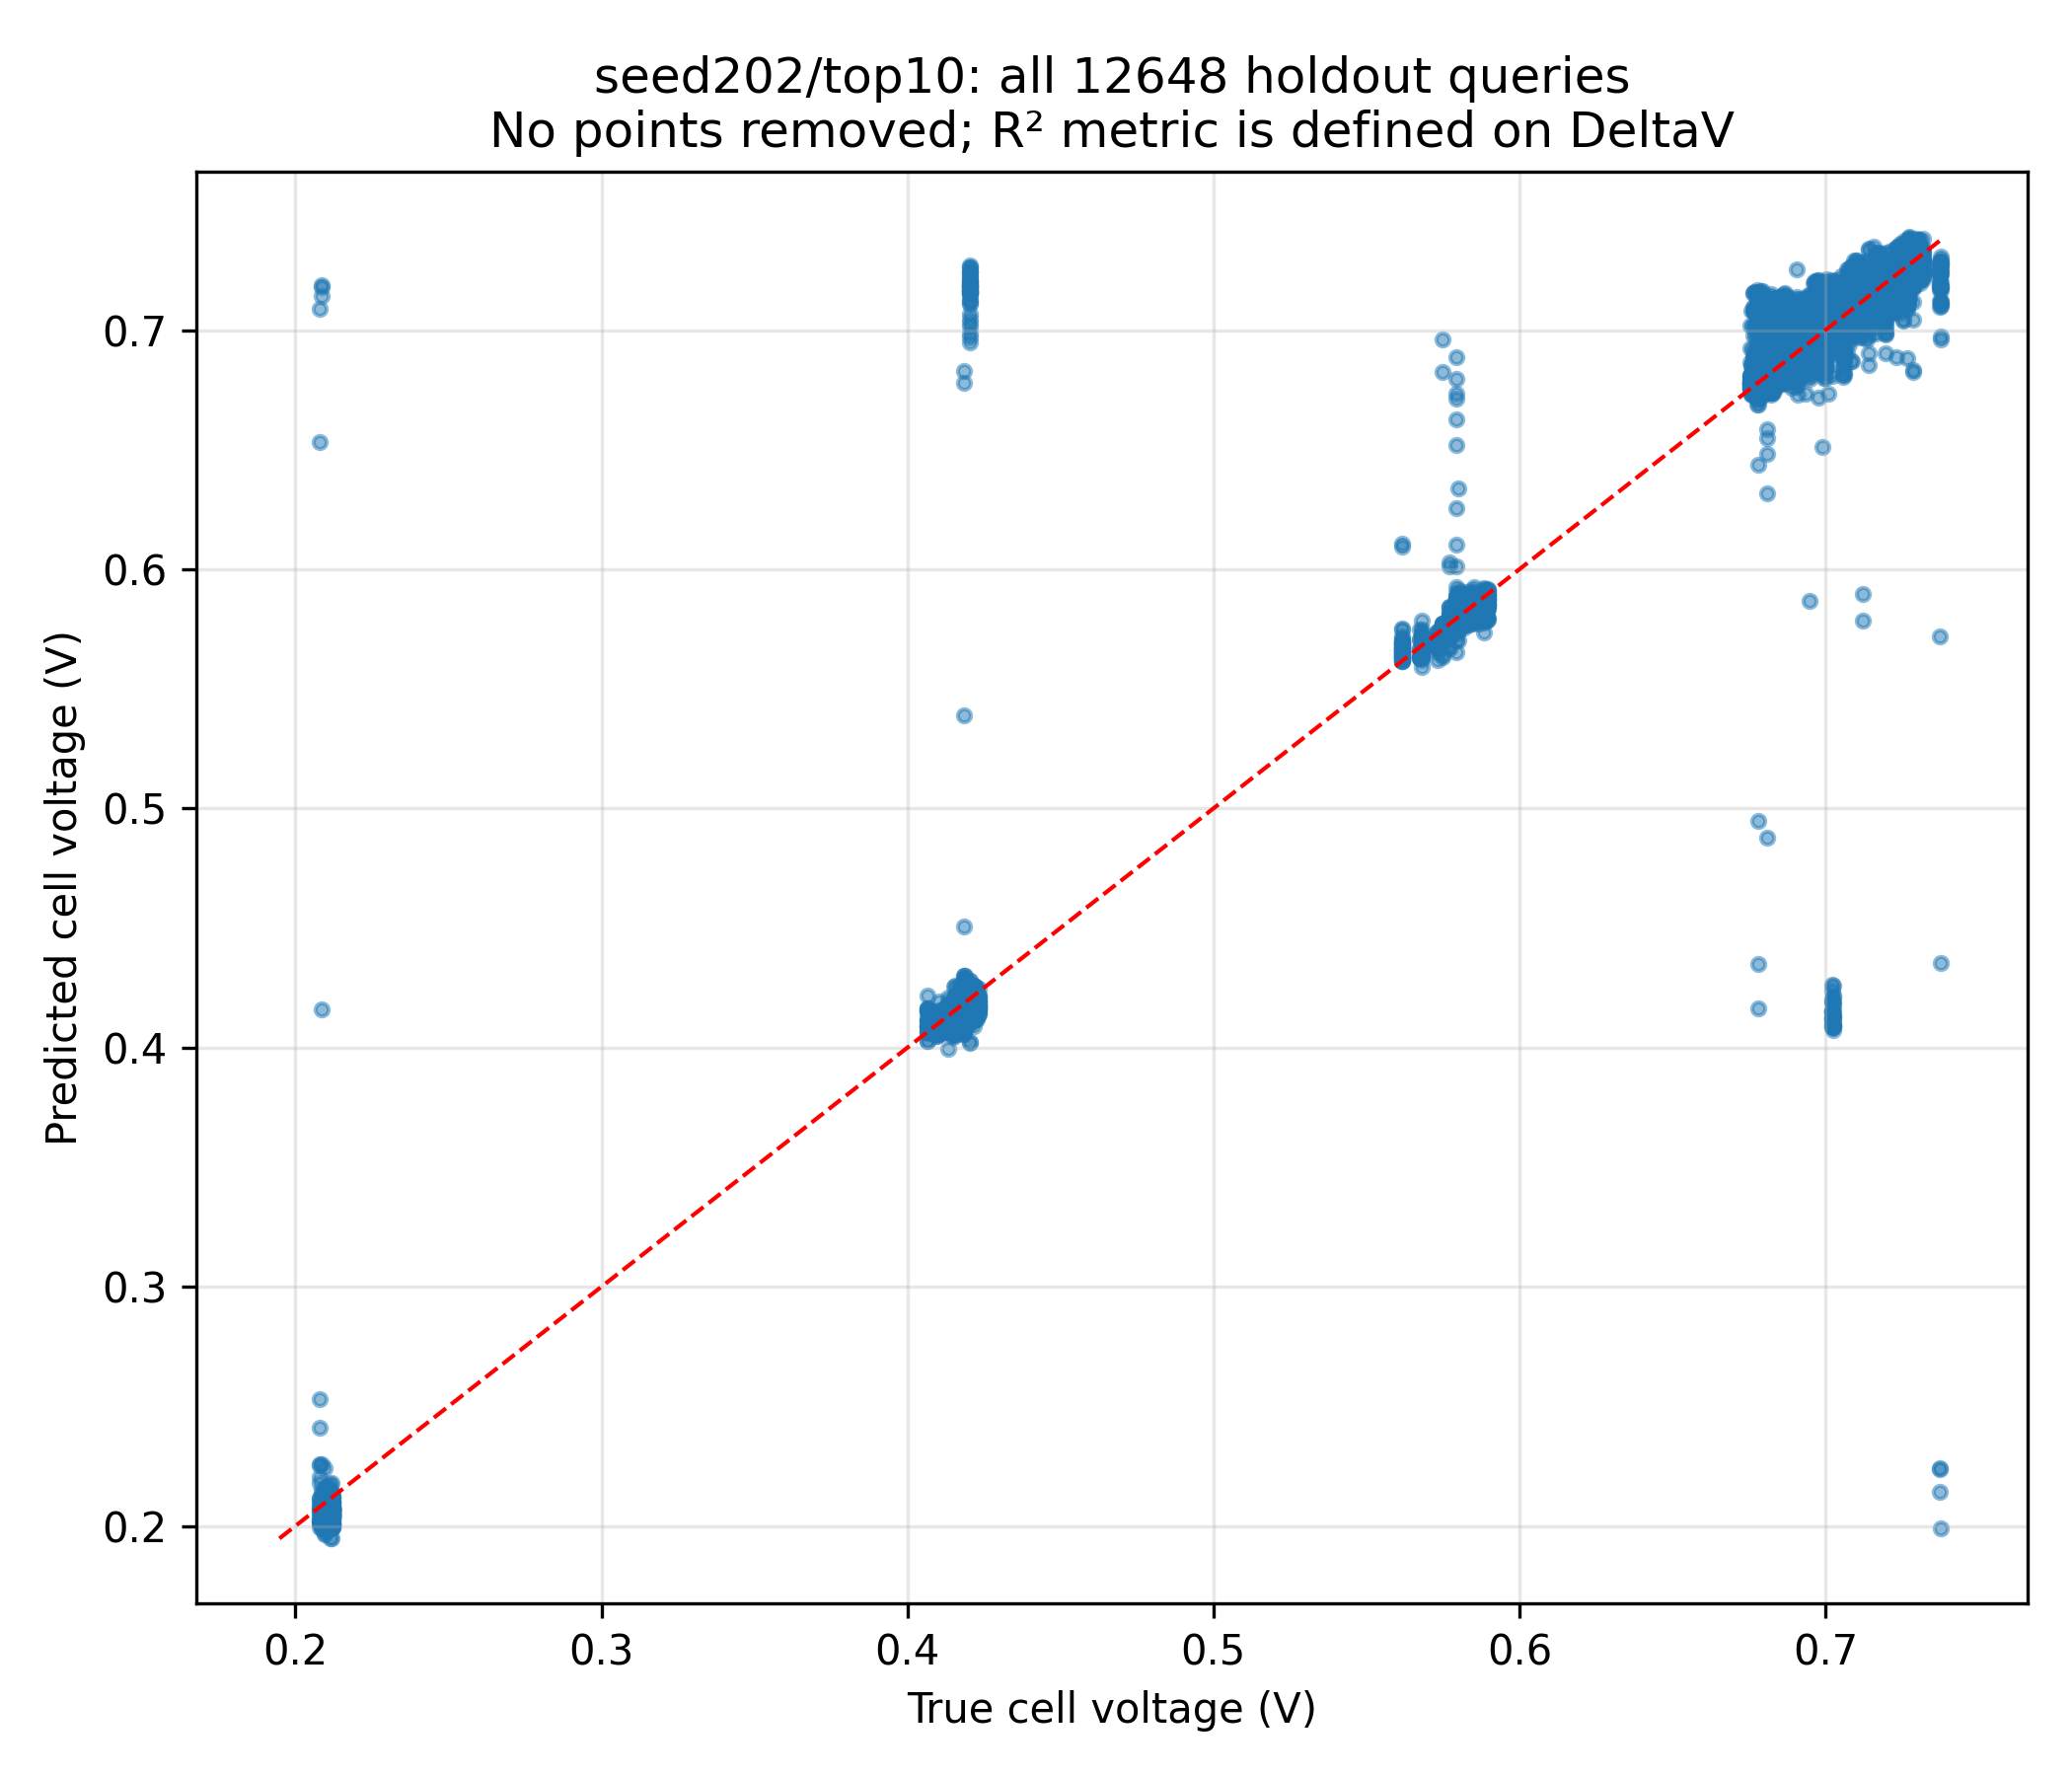

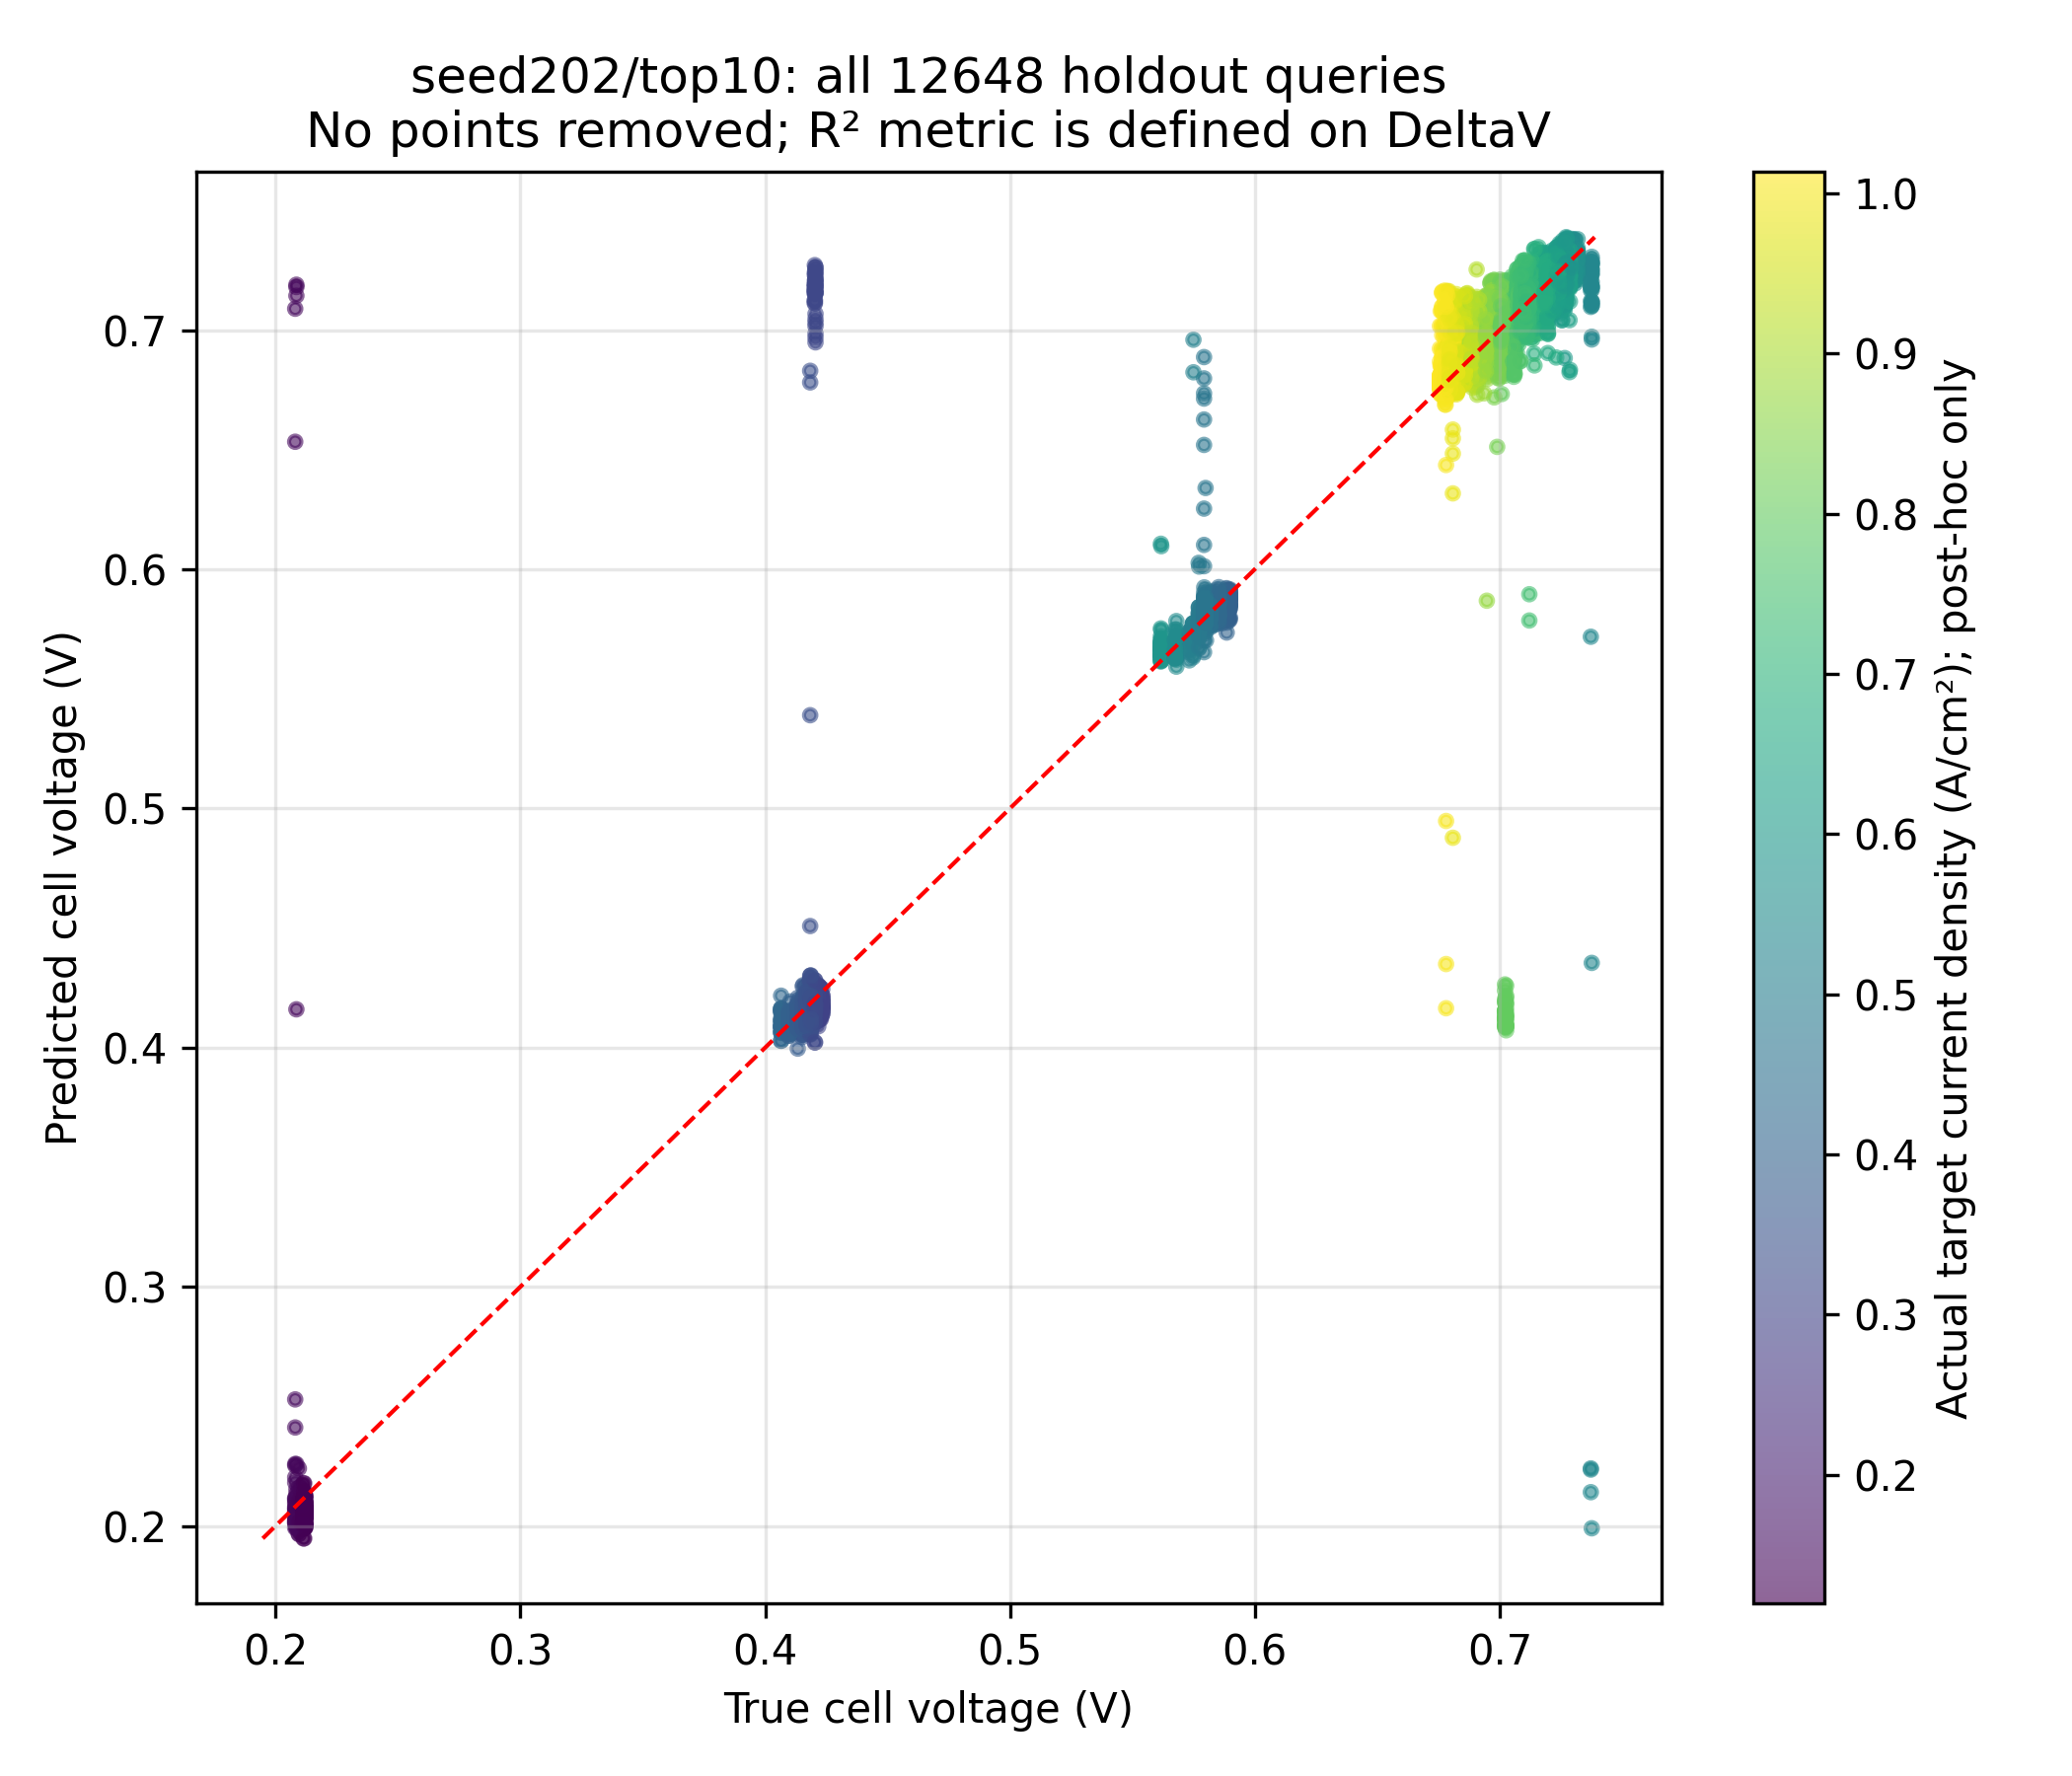

,voltage_group,unique_target_times,voltage_min_V,voltage_max_V,current_density_median,current_density_P10,current_density_P90
0,0,33,0.208021,0.212171,0.122665,0.119992,0.133295
1,1,63,0.406503,0.423326,0.337859,0.303569,0.371403
2,2,31,0.561632,0.589831,0.457551,0.394009,0.546768
3,3,492,0.675592,0.737631,0.764294,0.603829,0.996308


本次最佳权重推理：Seed 202 top11 TRAIN，1750个窗口
本次最佳权重推理：Seed 202 top11 VALIDATION，218个窗口
本次最佳权重推理：Seed 202 top11 TEST，527个窗口


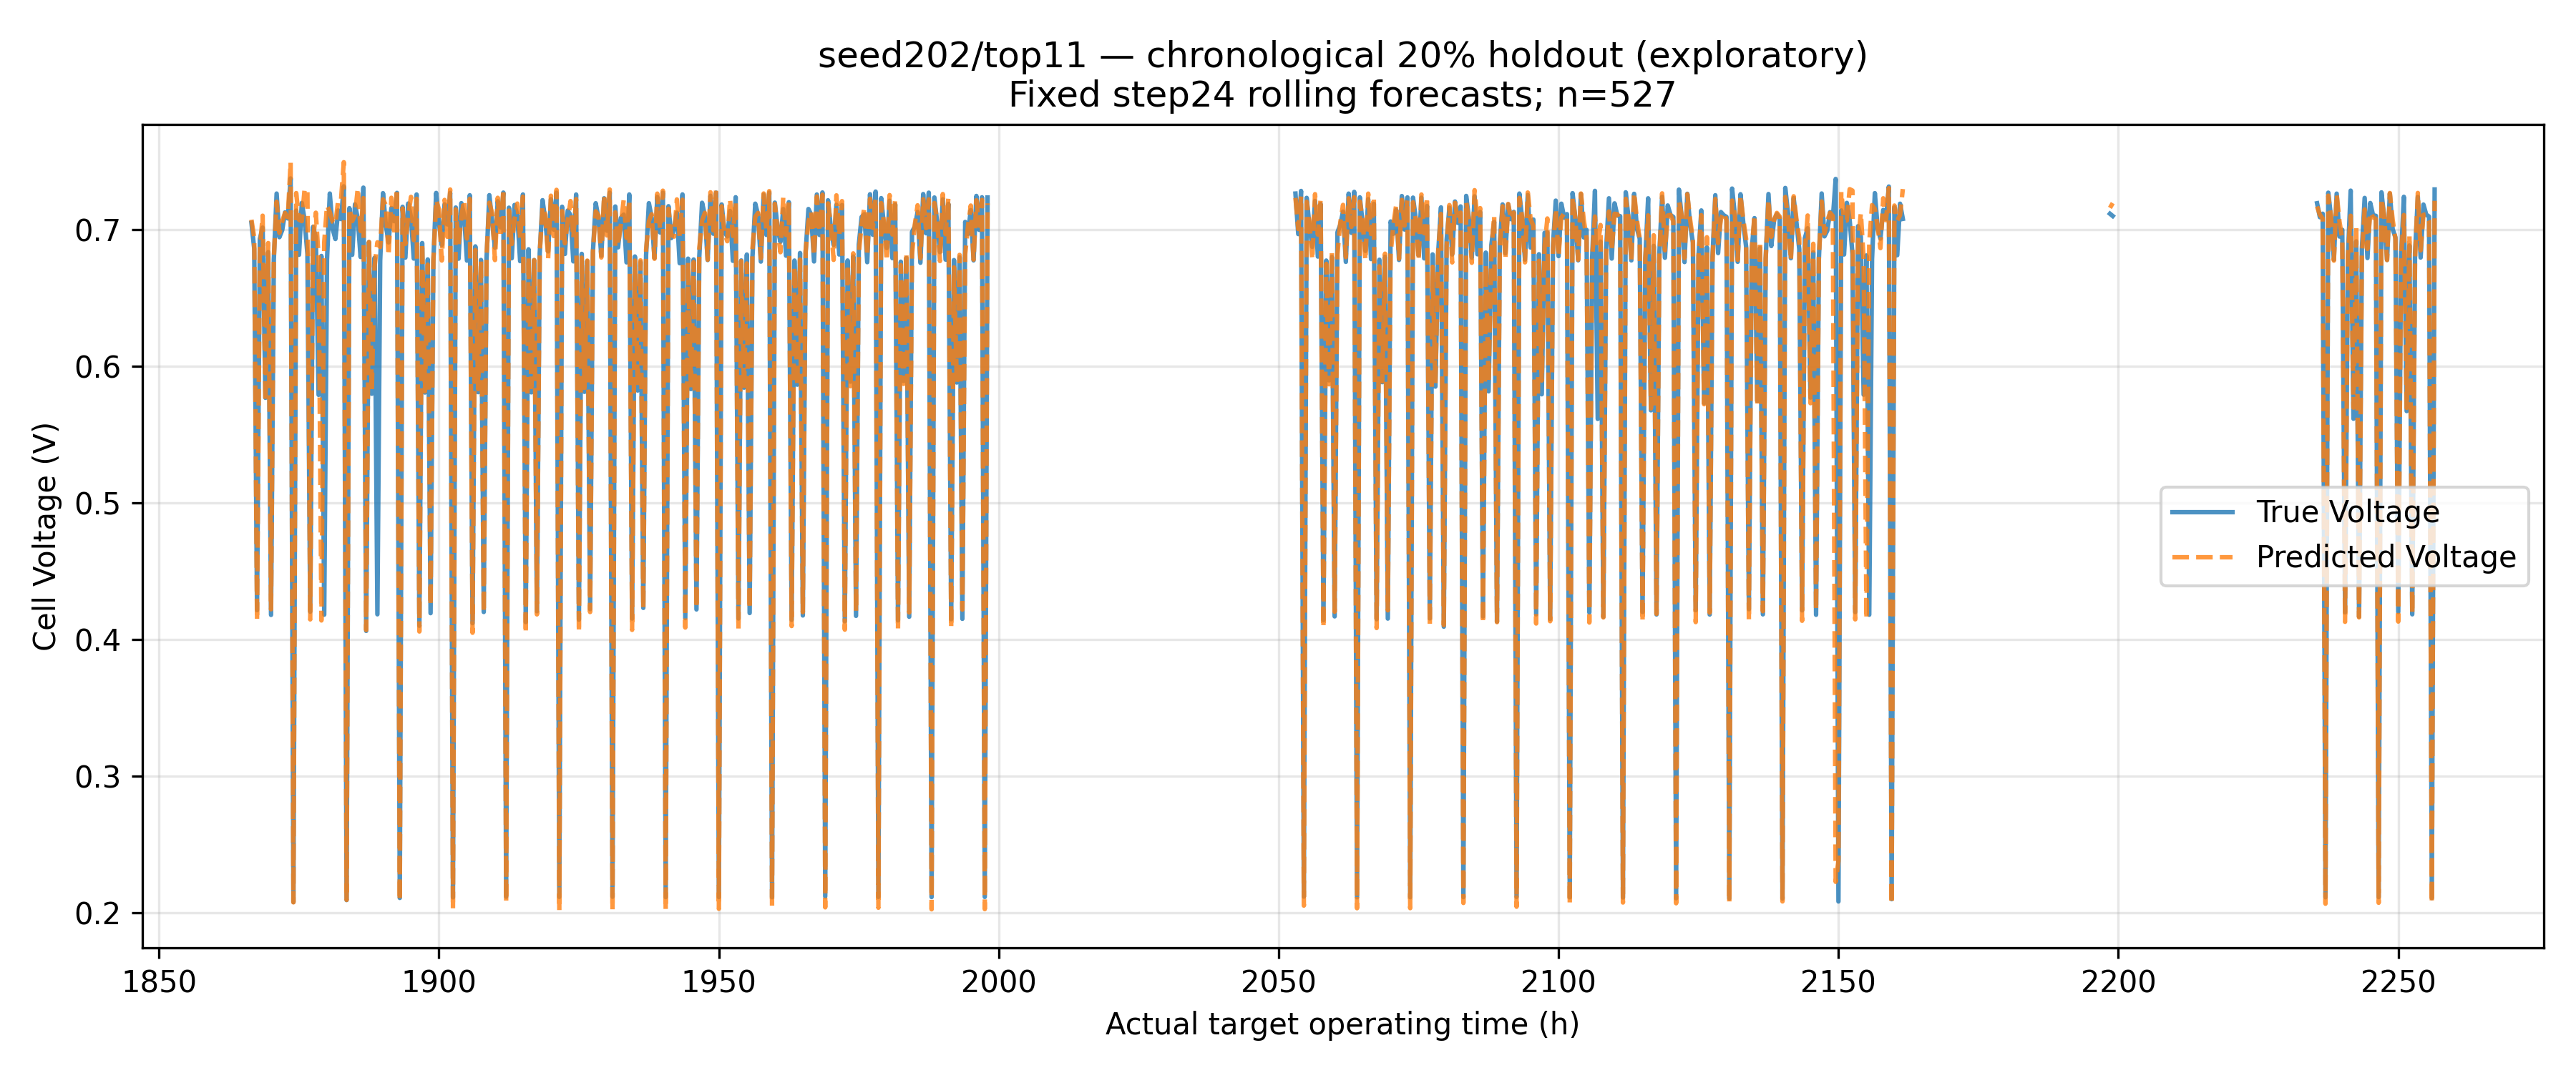

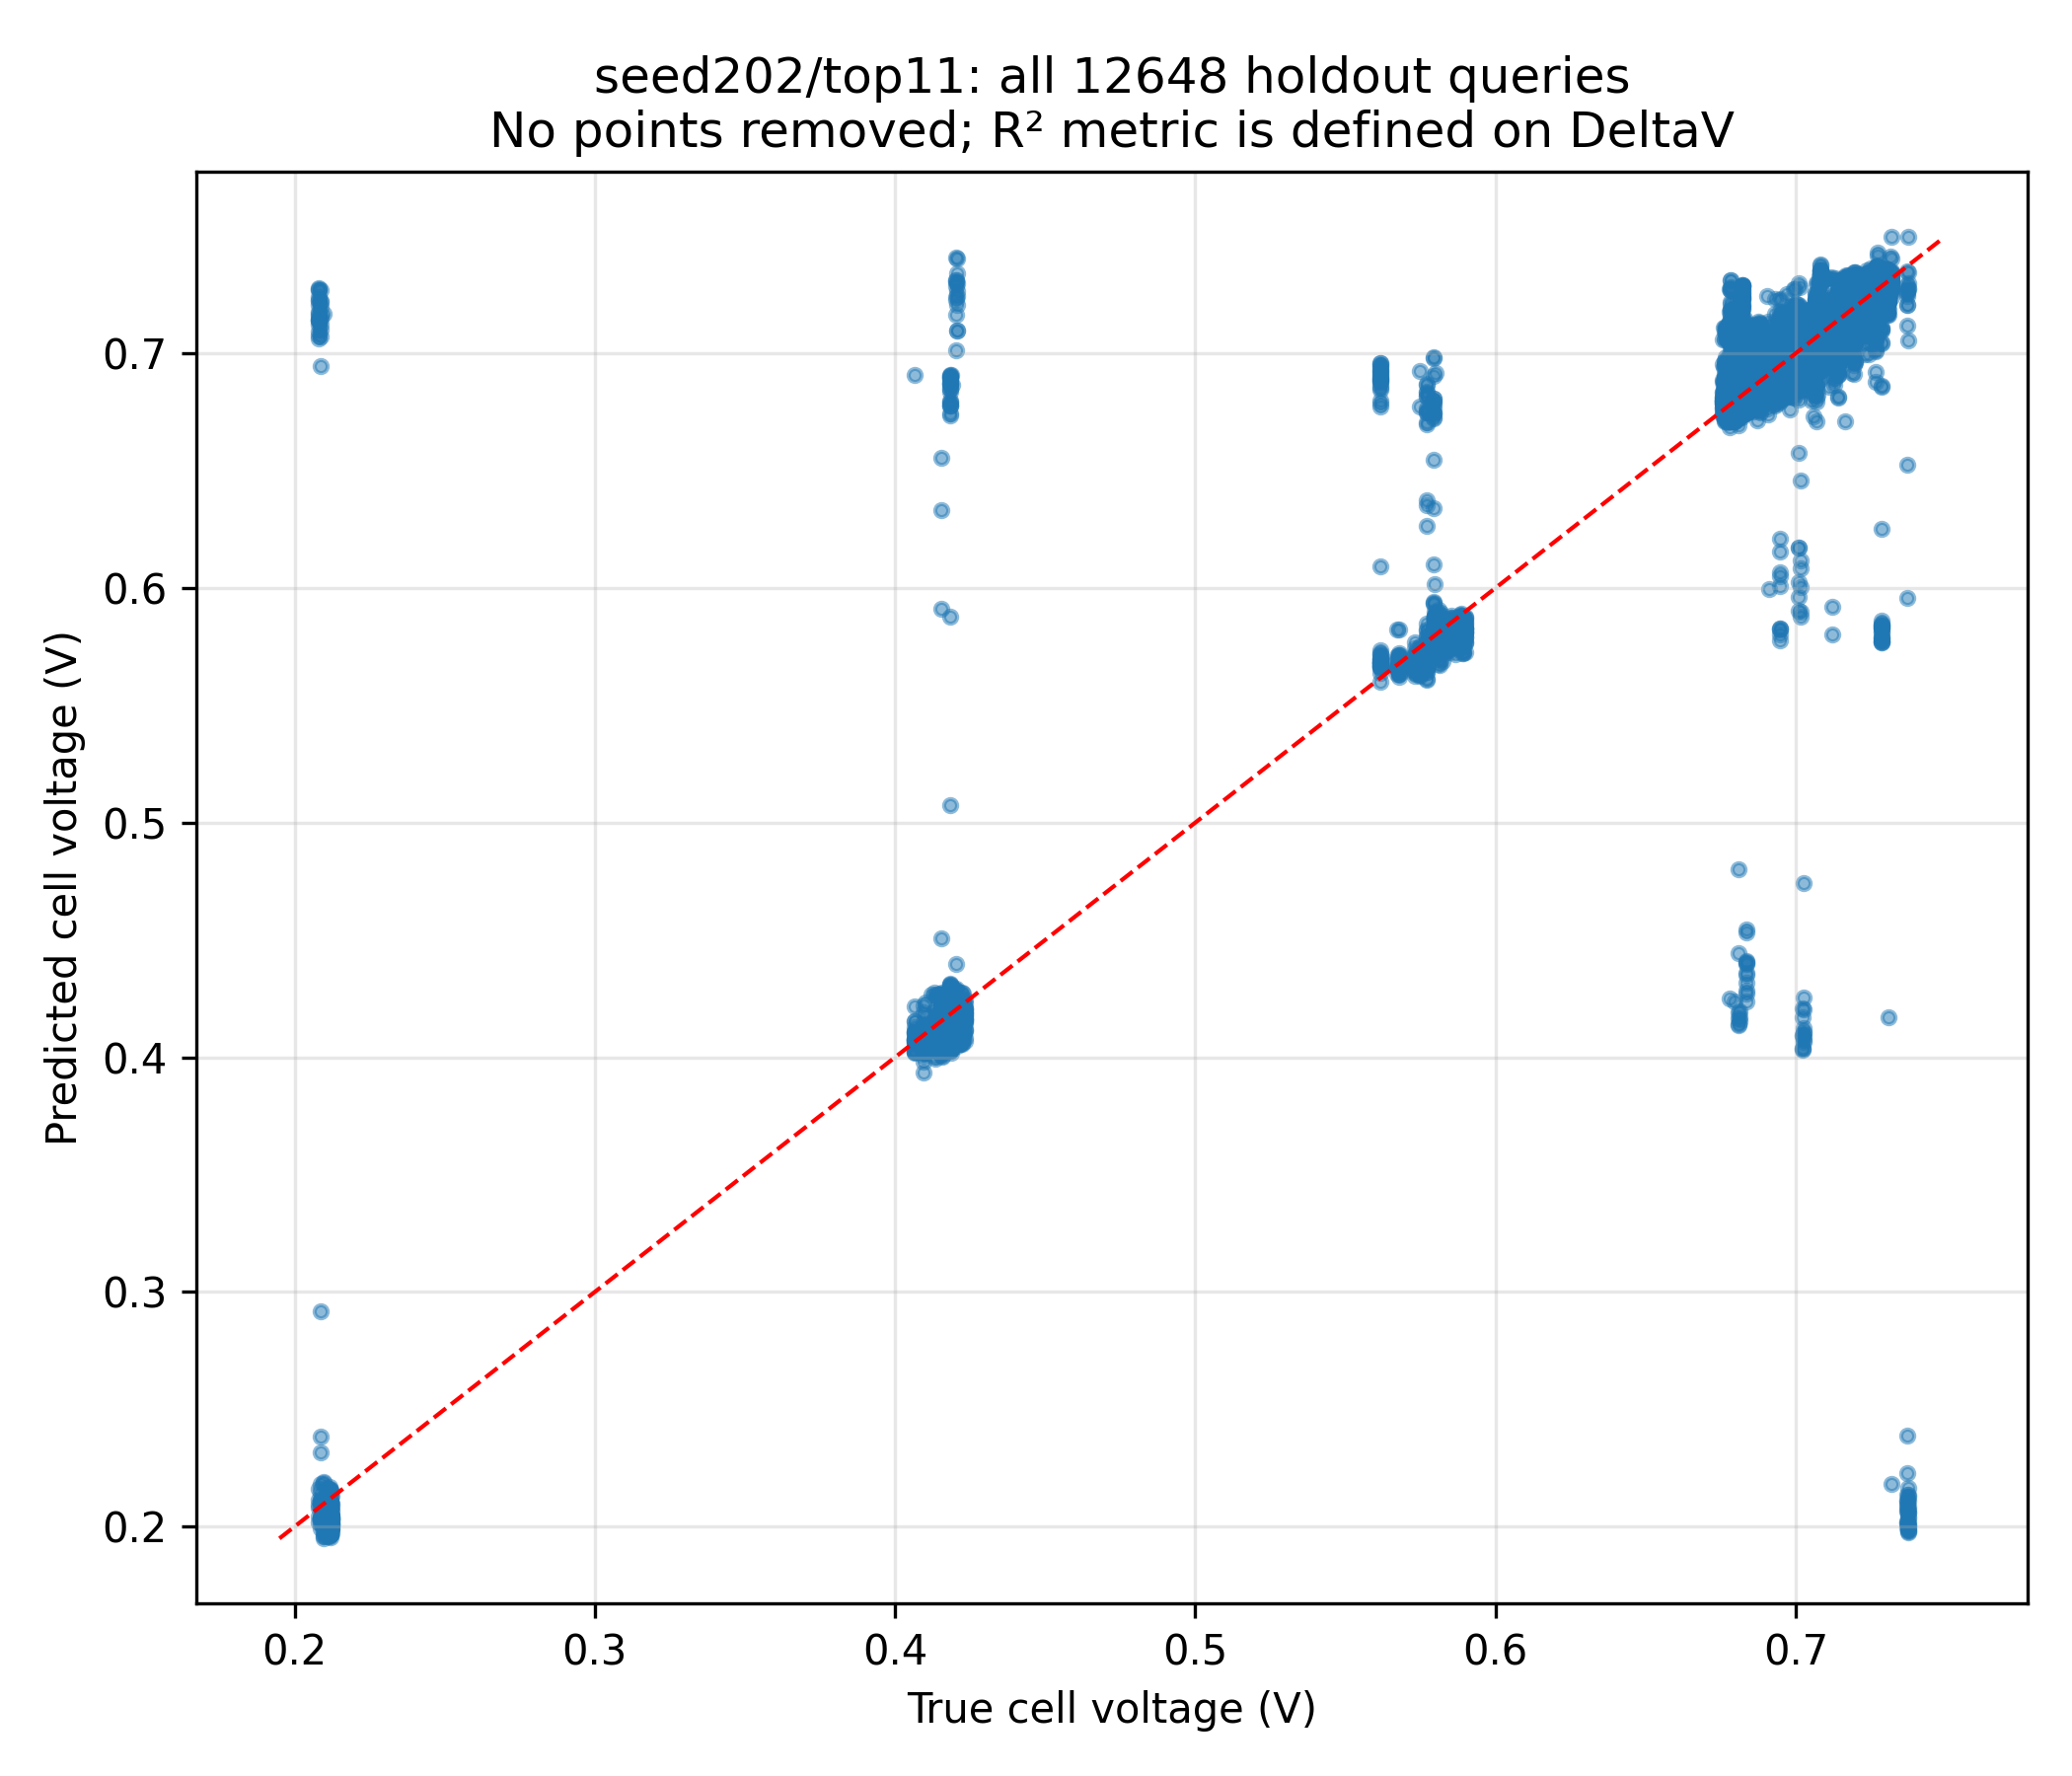

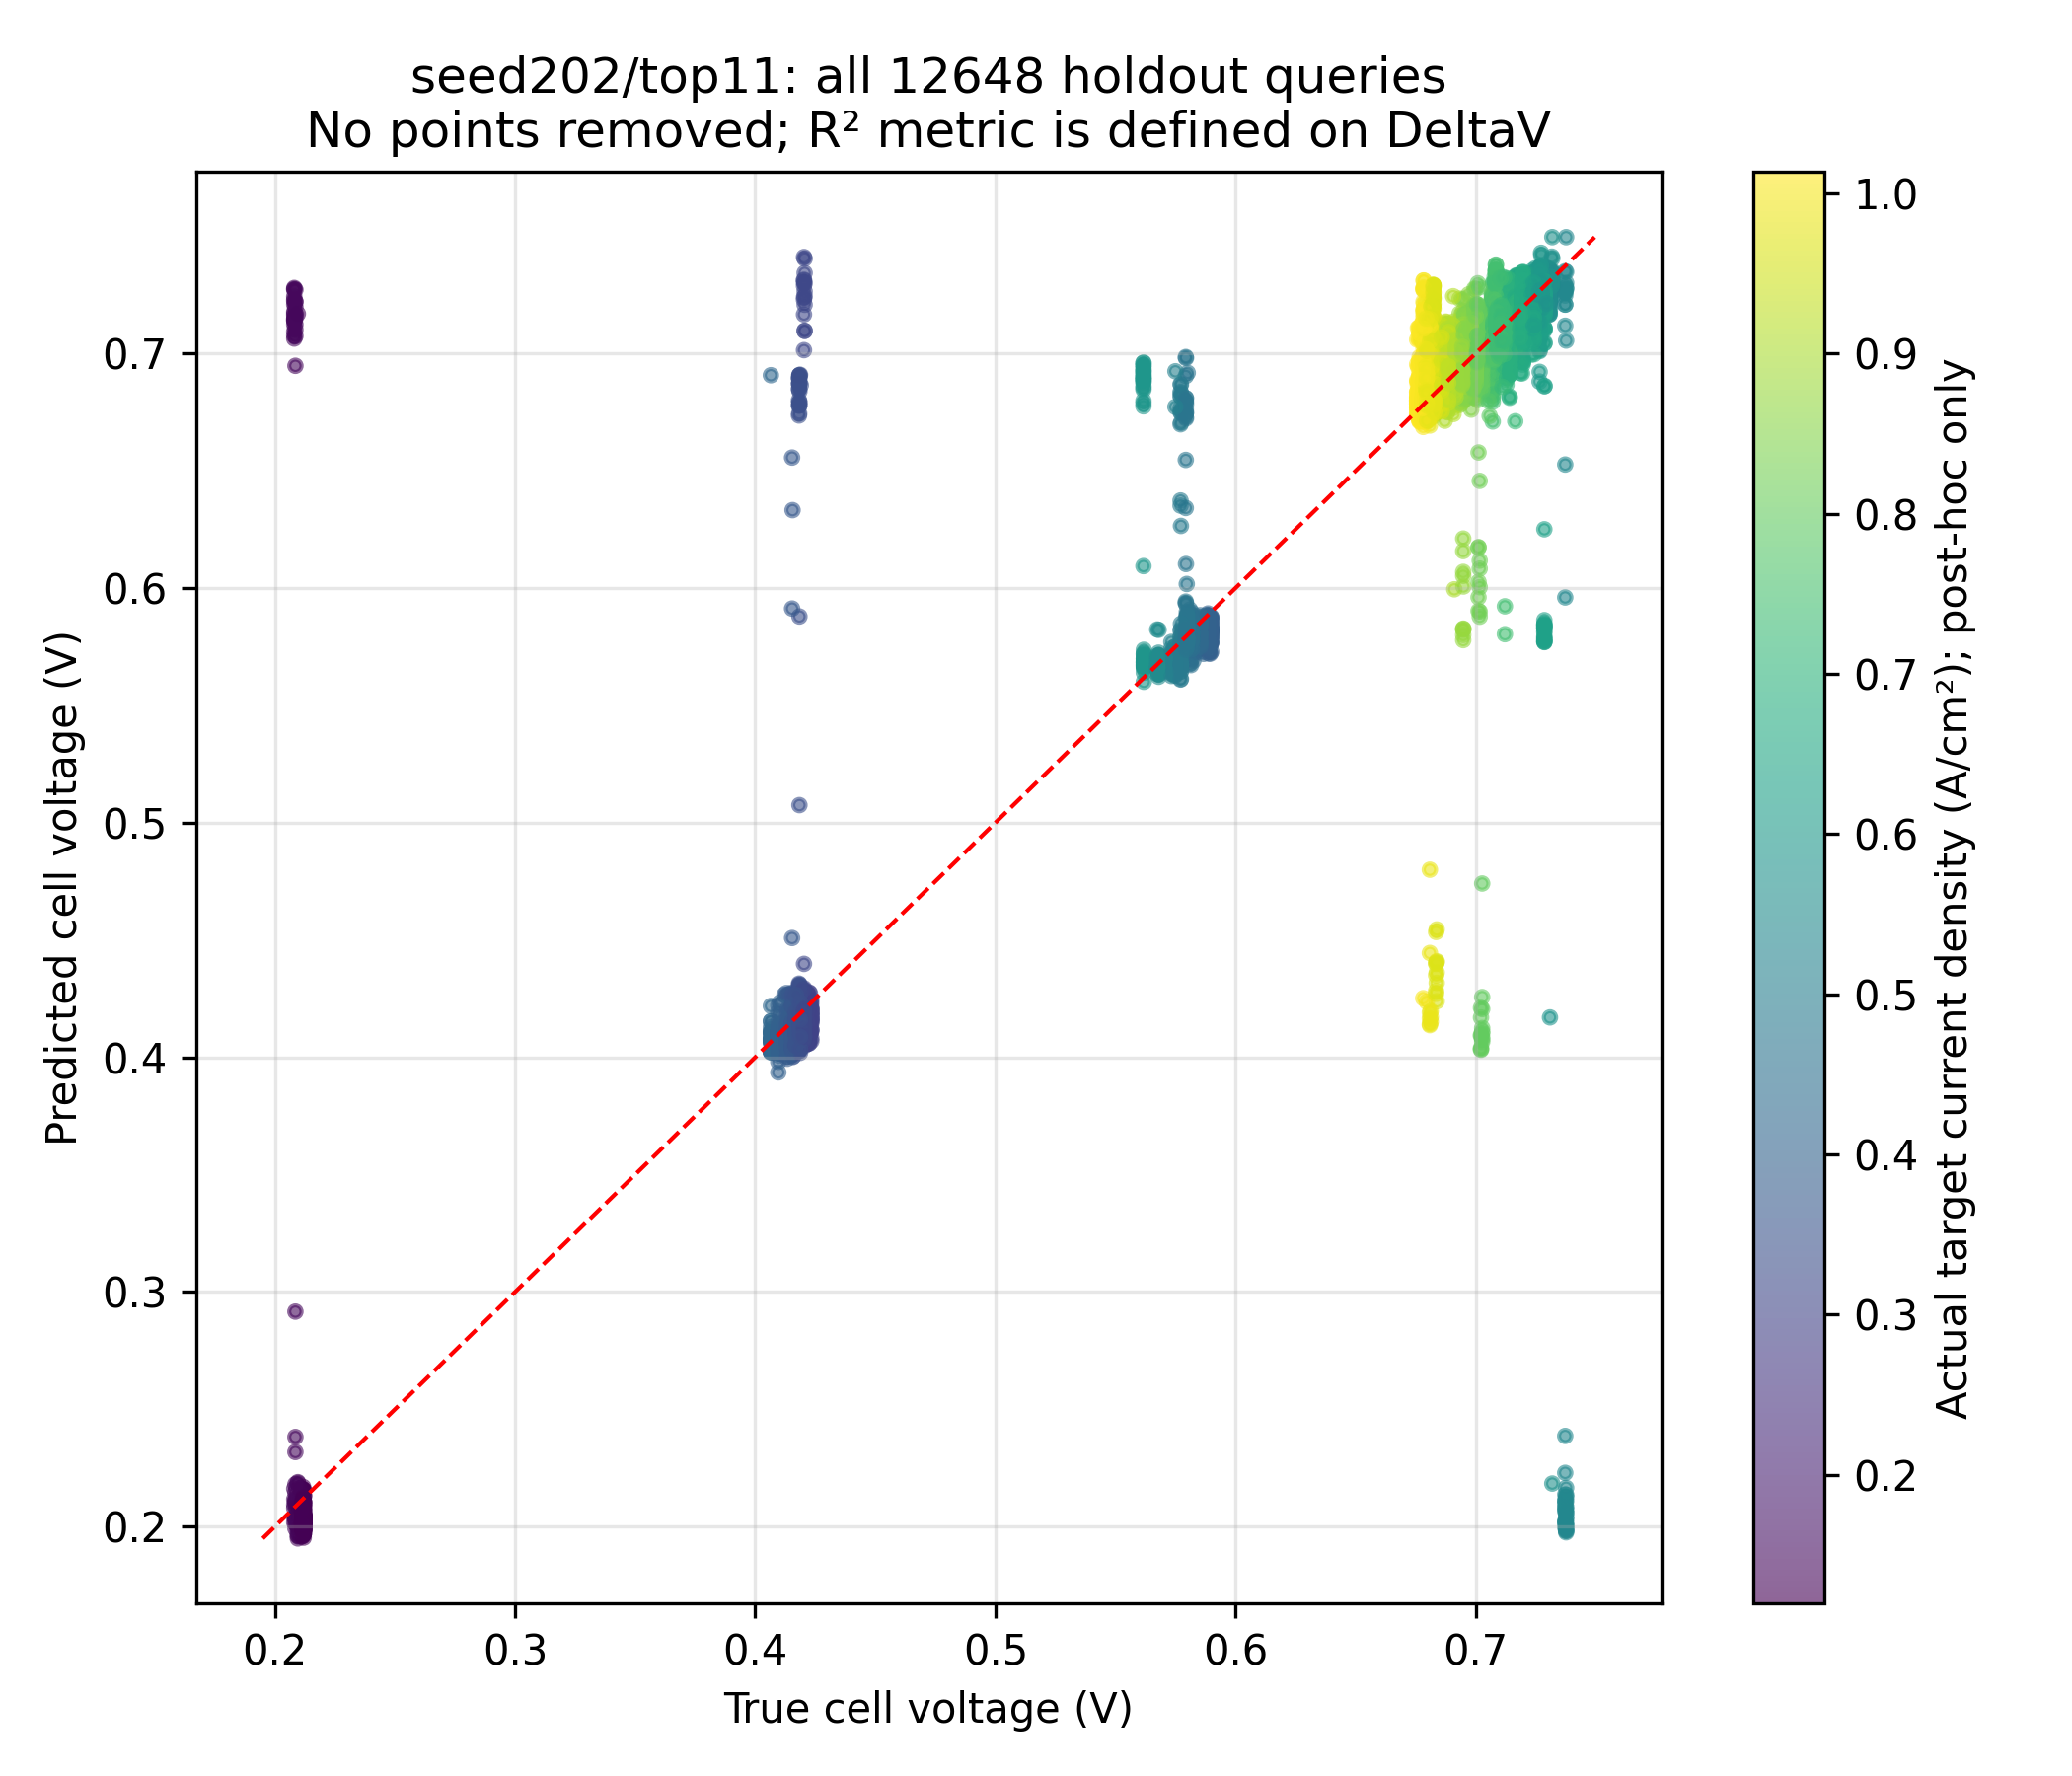

,voltage_group,unique_target_times,voltage_min_V,voltage_max_V,current_density_median,current_density_P10,current_density_P90
0,0,33,0.208021,0.212171,0.122665,0.119992,0.133295
1,1,63,0.406503,0.423326,0.337859,0.303569,0.371403
2,2,31,0.561632,0.589831,0.457551,0.394009,0.546768
3,3,492,0.675592,0.737631,0.764294,0.603829,0.996308


In [8]:
all_metrics = []
for ledger in training_ledgers:
    seed, mode = ledger['seed'], ledger['feature_mode']
    all_metrics.extend(evaluate_new_checkpoint(run, seed, mode, ledger, frame, windows,
                                             prepared_by_mode[mode], scaler, voltage_edges))

In [9]:
averages, differences = finalize_results(run, all_metrics, modes, seeds)
display(Markdown('**散点解释边界：** 着色采用目标时刻实际电流密度，仅用于事后工况诊断，未进入预测器。'
    '电压分组边界仅在Train上拟合，四组是固定描述性分组，不能据此宣称存在恰好四种独立物理状态。'
    '请结合各组电流密度中位数和P10/P90判断负载差异与重叠，不凭电压聚集直接认定模型异常或电池退化。'))
require(sha(SOURCE) == protocol['data_sha256'], 'SOURCE_CHANGED')
save_json(run, 'TRAINING_ACCEPTANCE.json', dict(status='PASS', run_id=run.name, seeds=seeds, feature_modes=modes,
    fresh_models=len(training_ledgers), total_optimizer_steps=sum(row['optimizer_steps'] for row in training_ledgers),
    total_backward_calls=sum(row['backward_calls'] for row in training_ledgers), trained_from_scratch=True,
    historical_checkpoint_loaded=False, same_split_and_metric=True, model_architecture_unchanged=True,
    averages=averages, differences=differences, historical_results_overwritten=False))
save_csv(run, 'ARTIFACT_MANIFEST.csv', [dict(path=path.relative_to(run).as_posix(), sha256=sha(path))
    for path in sorted(run.rglob('*')) if path.is_file() and path.name != 'ARTIFACT_MANIFEST.csv'])
print(f'本次训练及评价全部完成，输出：{run}', flush=True)

### 本次真实训练结果：后20%时间后留评价（探索性，非独立盲测）

,seed,feature_mode,RMSE_V,MAE_V,R2
2,202,top10,0.028466,0.006685,0.978452
5,202,top11,0.044440,0.010741,0.947484


,feature_mode,seeds,RMSE_V,MAE_V,R2
0,top10,202,0.028466,0.006685,0.978452
1,top11,202,0.044440,0.010741,0.947484


,seed,RMSE_V_top11_minus_top10,MAE_V_top11_minus_top10,R2_top11_minus_top10
0,202,0.015974,0.004056,-0.030968
1,mean,0.015974,0.004056,-0.030968


**散点解释边界：** 着色采用目标时刻实际电流密度，仅用于事后工况诊断，未进入预测器。电压分组边界仅在Train上拟合，四组是固定描述性分组，不能据此宣称存在恰好四种独立物理状态。请结合各组电流密度中位数和P10/P90判断负载差异与重叠，不凭电压聚集直接认定模型异常或电池退化。

本次训练及评价全部完成，输出：E:\沈农信电\ PEMFC-SOH+RUL\RENew-PEMFC-2300h-Pytorch\REAL_Paper_File\F2主程序\F2_Training_Outputs\20261019T052754_499042Z_seed202_compare
